## 1. Загрузка и дескриптивный анализ данных

**Цель работы:** изучить алгоритмы кластеризации, оценить качество и устойчивость разбиений,
дать содержательную интерпретацию выделенных групп.

**Задача:** сгруппировать населённые пункты США по социально-экономическим, жилищным
и демографическим характеристикам; затем сравнить полученные группы по уровню преступности.
Используются два метода: **K-means** и **иерархическая кластеризация Уорда**.

Показатели преступности и идентификаторы не входят в пространство кластеризации.
`ViolentCrimesPerPop` используется только после выбора моделей, для интерпретации и условной
внешней оценки. Наблюдения без этого показателя участвуют в кластеризации.

Один объект — населённый пункт. В файле нет заголовка; названия столбцов соответствуют
предыдущим лабораторным. Символ `?` обозначает пропуск. Проверим размерность, типы,
полноту данных, дубликаты и описательные статистики.

In [1]:
from pathlib import Path
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from IPython.display import display
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from scipy.spatial.distance import pdist, cdist
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score,
    davies_bouldin_score, adjusted_rand_score, rand_score,
    normalized_mutual_info_score, pairwise_distances,
)
from sklearn.metrics.cluster import pair_confusion_matrix
from threadpoolctl import threadpool_limits

RANDOM_STATE = 42
thread_limit = threadpool_limits(limits=1)
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 110, 'axes.unicode_minus': False})
pd.set_option('display.max_columns', 18)
pd.set_option('display.width', 180)

DATA_PATH = Path('data') / 'DATASET.txt'
if not DATA_PATH.exists():
    raise FileNotFoundError('Откройте ноутбук из каталога проекта, содержащего data/DATASET.txt.')
print(f'Python {platform.python_version()}; pandas {pd.__version__}; '
      f'scikit-learn {sklearn.__version__}; SciPy {scipy.__version__}')

Python 3.9.13; pandas 2.3.3; scikit-learn 1.6.1; SciPy 1.13.1


Размерность исходных данных: 2215 объектов × 147 столбцов.
Типы данных:


,Количество столбцов
float64,116
int64,29
object,2


,communityname,State,population,medIncome,ViolentCrimesPerPop
0,BerkeleyHeightstownship,NJ,11980,75122,41.02
1,Marpletownship,PA,23123,47917,127.56
2,Tigardcity,OR,29344,35669,218.59
3,Gloversvillecity,NY,16656,20580,306.64
4,Bemidjicity,MN,11245,17390,NaN


Полных дубликатов строк: 0.
Столбцов с пропусками: 41; с долей пропусков > 50%: 24.


,Тип,Пропуски,"Пропуски, %",Уникальных значений
PctPolicBlack,float64,1872,84.51,288
PolicReqPerOffic,float64,1872,84.51,336
PolicPerPop,float64,1872,84.51,322
PolicCars,float64,1872,84.51,193
PolicOperBudg,float64,1872,84.51,341
LemasPctPolicOnPatr,float64,1872,84.51,307
PolicAveOTWorked,float64,1872,84.51,304
LemasGangUnitDeploy,float64,1872,84.51,3
PolicBudgPerPop,float64,1872,84.51,343
PctPolicWhite,float64,1872,84.51,317


,count,mean,std,min,25%,50%,75%,max
countyCode,994.0,65.59,117.83,1.00,11.00,27.00,80.50,840.00
communityCode,991.0,45209.25,25425.86,70.00,22887.00,46925.00,65805.00,94597.00
fold,2215.0,5.49,2.87,1.00,3.00,5.00,8.00,10.00
population,2215.0,53117.98,204620.25,10005.00,14366.00,22792.00,43024.00,7322564.00
householdsize,2215.0,2.71,0.33,1.60,2.50,2.66,2.85,5.28
...,...,...,...,...,...,...,...,...
autoTheftPerPop,2212.0,473.97,504.67,6.55,156.95,302.36,589.78,4968.59
arsons,2124.0,30.91,180.13,0.00,1.00,5.00,16.00,5119.00
arsonsPerPop,2124.0,32.15,39.24,0.00,7.67,21.08,42.85,436.37
ViolentCrimesPerPop,1994.0,589.08,614.78,0.00,161.70,374.06,794.40,4877.06


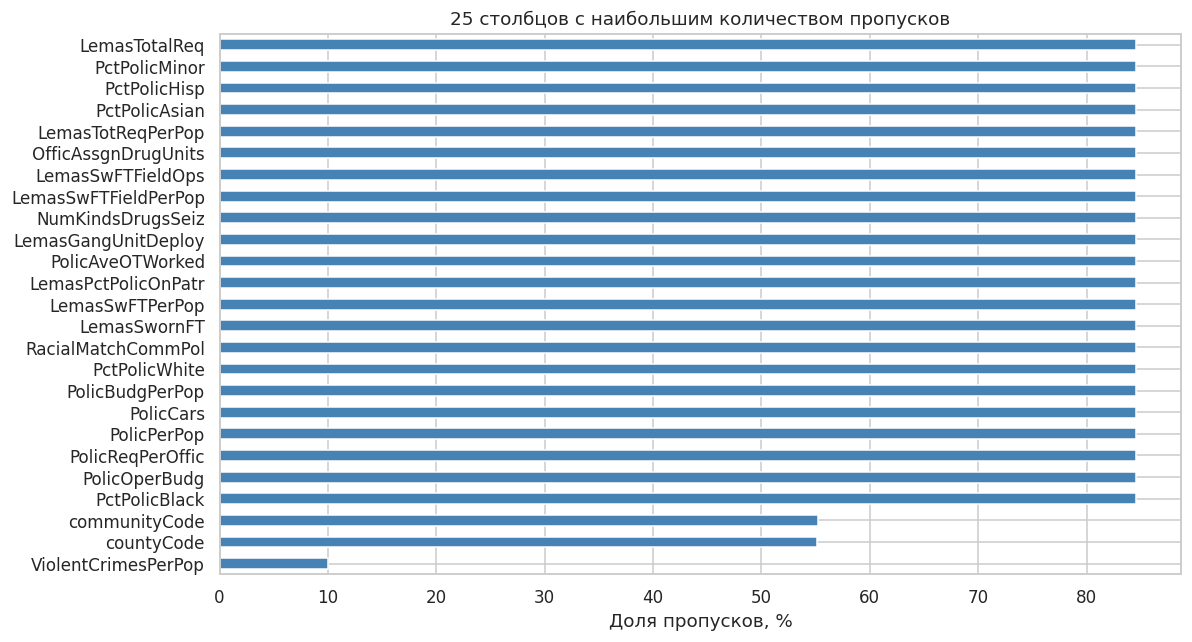

In [2]:
column_names = ['communityname', 'State', 'countyCode', 'communityCode', 'fold', 'population', 'householdsize', 'racepctblack', 'racePctWhite', 'racePctAsian', 'racePctHisp', 'agePct12t21', 'agePct12t29', 'agePct16t24', 'agePct65up', 'numbUrban', 'pctUrban', 'medIncome', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'medFamInc', 'perCapInc', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'NumUnderPov', 'PctPopUnderPov', 'PctLess9thGrade', 'PctNotHSGrad', 'PctBSorMore', 'PctUnemployed', 'PctEmploy', 'PctEmplManu', 'PctEmplProfServ', 'PctOccupManu', 'PctOccupMgmtProf', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'TotalPctDiv', 'PersPerFam', 'PctFam2Par', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMomYoungKids', 'PctWorkMom', 'NumKidsBornNeverMar', 'PctKidsBornNeverMar', 'NumImmig', 'PctImmigRecent', 'PctImmigRec5', 'PctImmigRec8', 'PctImmigRec10', 'PctRecentImmig', 'PctRecImmig5', 'PctRecImmig8', 'PctRecImmig10', 'PctSpeakEnglOnly', 'PctNotSpeakEnglWell', 'PctLargHouseFam', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PersPerRentOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctHousOwnOcc', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'OwnOccMedVal', 'OwnOccHiQuart', 'OwnOccQrange', 'RentLowQ', 'RentMedian', 'RentHighQ', 'RentQrange', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctBornSameState', 'PctSameHouse85', 'PctSameCity85', 'PctSameState85', 'LemasSwornFT', 'LemasSwFTPerPop', 'LemasSwFTFieldOps', 'LemasSwFTFieldPerPop', 'LemasTotalReq', 'LemasTotReqPerPop', 'PolicReqPerOffic', 'PolicPerPop', 'RacialMatchCommPol', 'PctPolicWhite', 'PctPolicBlack', 'PctPolicHisp', 'PctPolicAsian', 'PctPolicMinor', 'OfficAssgnDrugUnits', 'NumKindsDrugsSeiz', 'PolicAveOTWorked', 'LandArea', 'PopDens', 'PctUsePubTrans', 'PolicCars', 'PolicOperBudg', 'LemasPctPolicOnPatr', 'LemasGangUnitDeploy', 'LemasPctOfficDrugUn', 'PolicBudgPerPop', 'murders', 'murdPerPop', 'rapes', 'rapesPerPop', 'robberies', 'robbbPerPop', 'assaults', 'assaultPerPop', 'burglaries', 'burglPerPop', 'larcenies', 'larcPerPop', 'autoTheft', 'autoTheftPerPop', 'arsons', 'arsonsPerPop', 'ViolentCrimesPerPop', 'nonViolPerPop']

df = pd.read_csv(DATA_PATH, header=None, na_values='?')
assert df.shape[1] == len(column_names), 'Число столбцов не соответствует схеме.'
df.columns = column_names

SERVICE_COLUMNS = ['communityname', 'State', 'countyCode', 'communityCode', 'fold']
CRIME_COLUMNS = [
    'murders', 'murdPerPop', 'rapes', 'rapesPerPop', 'robberies', 'robbbPerPop',
    'assaults', 'assaultPerPop', 'burglaries', 'burglPerPop', 'larcenies', 'larcPerPop',
    'autoTheft', 'autoTheftPerPop', 'arsons', 'arsonsPerPop',
    'ViolentCrimesPerPop', 'nonViolPerPop',
]
TARGET = 'ViolentCrimesPerPop'
print(f'Размерность исходных данных: {df.shape[0]} объектов × {df.shape[1]} столбцов.')
print('Типы данных:')
display(df.dtypes.astype(str).value_counts().rename('Количество столбцов').to_frame())
display(df[['communityname', 'State', 'population', 'medIncome', TARGET]].head())

data_audit = pd.DataFrame({
    'Тип': df.dtypes.astype(str),
    'Пропуски': df.isna().sum(),
    'Пропуски, %': df.isna().mean() * 100,
    'Уникальных значений': df.nunique(),
}).sort_values('Пропуски', ascending=False)
print(f'Полных дубликатов строк: {df.duplicated().sum()}.')
print(f'Столбцов с пропусками: {df.isna().any().sum()}; '
      f'с долей пропусков > 50%: {(df.isna().mean() > 0.5).sum()}.')
display(data_audit.head(25).round(2))
display(df.select_dtypes(include='number').describe().T.round(2))

fig, ax = plt.subplots(figsize=(11, 6))
missing_top = (df.isna().mean() * 100).sort_values(ascending=False).head(25).sort_values()
missing_top.plot.barh(ax=ax, color='steelblue')
ax.set(xlabel='Доля пропусков, %', title='25 столбцов с наибольшим количеством пропусков')
plt.tight_layout()
plt.show()

Исходный набор содержит **2215 населённых пунктов и 147 столбцов**. Данные преимущественно числовые; текстовые столбцы обозначают название населённого пункта и штат. Полных дубликатов строк нет. Пропуски присутствуют в 41 столбце, причём в 24 столбцах их больше 50%. Поэтому удаление всех неполных строк до отбора признаков привело бы к неоправданной потере наблюдений. Сначала выбираются характеристики для конкретной задачи кластеризации.

## 2. Выбор и информационная значимость признаков

В кластеризации нет целевого класса, поэтому корреляция с преступностью и качество
классификатора не используются для отбора признаков. Сначала проверяются полнота,
вариативность и избыточность признаков, затем — их вклад в PCA и различия между кластерами.
Дисперсии в исходных единицах нельзя напрямую сравнивать как «важность».

Идентификаторы и fold исключаются. Из оставшихся характеристик исключаются признаки
с более чем 50% пропусков и константы. Для интерпретируемой модели выбираются 12 показателей,
описывающих доход, бедность, занятость, образование, семью, жильё, плотность и возраст.
Это ограничивает многократный учёт почти одинаковых характеристик из исходных 147 столбцов.
Если среди кандидатов есть пары с |r| > 0.85, сохраняется первый по заданному порядку.
Оставшиеся пропуски заполняются медианой; фактическое количество заполнений выводится ниже.

,Описание,"Пропуски, %",Уникальных значений,Стандартное отклонение,IQR,Выбран
medIncome,Медианный доход домохозяйства,0.0,2141,13424.680,17663.500,True
PctPopUnderPov,"Доля населения за чертой бедности, %",0.0,1462,8.600,12.395,True
PctUnemployed,"Доля безработных, %",0.0,868,2.896,3.395,True
PctBSorMore,"Доля жителей с высшим образованием, %",0.0,1660,12.687,14.960,True
PctKids2Par,"Доля детей, живущих с двумя родителями, %",0.0,1687,12.045,16.405,True
TotalPctDiv,"Доля разведённых, %",0.0,994,3.001,4.410,True
PctHousOwnOcc,"Доля жилья, занятого собственниками, %",0.0,1801,13.970,17.825,True
PctPersDenseHous,"Доля людей в перенаселённом жилье, %",0.0,850,5.599,3.440,True
PopDens,Плотность населения,0.0,2162,2828.993,2139.800,True
householdsize,Среднее число людей в домохозяйстве,0.0,198,0.334,0.350,True


Социально-экономических столбцов: 124; пригодных по полноте и вариативности: 102; выбрано: 12.
Исключённые избыточные пары: не обнаружены при пороге 0.85
Число заполняемых пропусков в выбранных признаках: 0


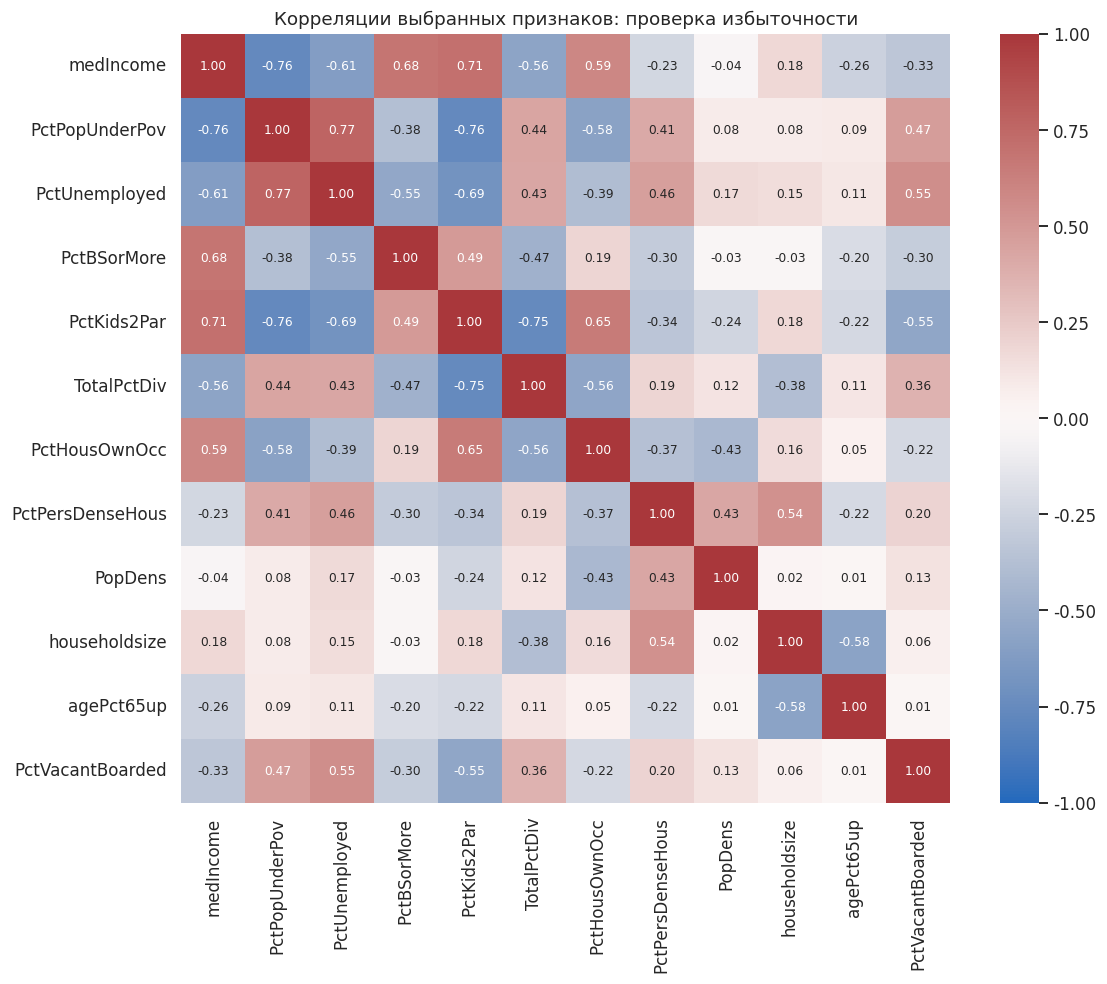

In [3]:
FEATURE_DESCRIPTIONS = {
    'medIncome': 'Медианный доход домохозяйства',
    'PctPopUnderPov': 'Доля населения за чертой бедности, %',
    'PctUnemployed': 'Доля безработных, %',
    'PctBSorMore': 'Доля жителей с высшим образованием, %',
    'PctKids2Par': 'Доля детей, живущих с двумя родителями, %',
    'TotalPctDiv': 'Доля разведённых, %',
    'PctHousOwnOcc': 'Доля жилья, занятого собственниками, %',
    'PctPersDenseHous': 'Доля людей в перенаселённом жилье, %',
    'PopDens': 'Плотность населения',
    'householdsize': 'Среднее число людей в домохозяйстве',
    'agePct65up': 'Доля жителей 65 лет и старше, %',
    'PctVacantBoarded': 'Доля заколоченных объектов среди пустующего жилья, %',
}
CANDIDATE_FEATURES = list(FEATURE_DESCRIPTIONS)
socioeconomic = df.drop(columns=SERVICE_COLUMNS + CRIME_COLUMNS).apply(pd.to_numeric, errors='coerce')
feature_audit = pd.DataFrame({
    'Пропуски, %': socioeconomic.isna().mean() * 100,
    'Уникальных значений': socioeconomic.nunique(),
    'Стандартное отклонение': socioeconomic.std(),
    'IQR': socioeconomic.quantile(0.75) - socioeconomic.quantile(0.25),
})
eligible = feature_audit.index[
    (feature_audit['Пропуски, %'] <= 50) & (feature_audit['Уникальных значений'] > 1)
].tolist()
correlation_candidates = socioeconomic[CANDIDATE_FEATURES].corr()
selected_features, redundant_features = [], []
for feature in CANDIDATE_FEATURES:
    if feature not in eligible:
        continue
    partners = [other for other in selected_features
                if abs(correlation_candidates.loc[feature, other]) > 0.85]
    if partners:
        redundant_features.append((feature, partners[0]))
    else:
        selected_features.append(feature)

selection_table = feature_audit.loc[CANDIDATE_FEATURES].copy()
selection_table.insert(0, 'Описание', pd.Series(FEATURE_DESCRIPTIONS))
selection_table['Выбран'] = selection_table.index.isin(selected_features)
display(selection_table.round(3))
print(f'Социально-экономических столбцов: {socioeconomic.shape[1]}; '
      f'пригодных по полноте и вариативности: {len(eligible)}; выбрано: {len(selected_features)}.')
print('Исключённые избыточные пары:', redundant_features or 'не обнаружены при пороге 0.85')

X_raw = socioeconomic[selected_features].copy()
print('Число заполняемых пропусков в выбранных признаках:', int(X_raw.isna().sum().sum()))
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X_raw), columns=selected_features, index=df.index)
assert not set(selected_features) & set(SERVICE_COLUMNS + CRIME_COLUMNS)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(X_imputed.corr(), cmap='vlag', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', square=True, ax=ax, annot_kws={'size': 8})
ax.set_title('Корреляции выбранных признаков: проверка избыточности')
plt.tight_layout()
plt.show()

После исключения служебных столбцов и показателей преступности остаётся 124 социально-экономических характеристики; 102 проходят проверку полноты и вариативности. Для модели выбраны **12 содержательно понятных признаков**, во всех них пропусков нет, поэтому медианное заполнение фактически не меняет данные. В исходных единицах максимальная корреляция по модулю составляет 0.773; пары выше порога 0.85 не обнаружены. Тем самым проверены полнота, вариативность и избыточность выбранного набора. Корреляции после преобразований рассматриваются отдельно.

## 3. Распределения признаков и проверка выбросов

Оценим форму распределений по гистограммам, коэффициенту асимметрии и тесту Д’Агостино — Пирсона
на нормальность (p < 0.05 — свидетельство против нормальности; поправка на множественные проверки
не применяется, тест используется как описательная диагностика). При большой выборке тест
чувствителен даже к небольшим отклонениям, поэтому вывод сопоставляется с гистограммами.
Нормальность отдельных признаков не является обязательным условием K-means и метода Уорда.

,Асимметрия,Эксцесс,p нормальности,p < 0.05
medIncome,1.348148,3.253180,3.689287e-126,True
PctPopUnderPov,1.115383,1.167139,6.075782e-80,True
PctUnemployed,1.751175,6.637358,6.507881e-190,True
PctBSorMore,1.233304,1.352504,8.914479e-93,True
PctKids2Par,-0.729667,0.499349,6.431361e-39,True
TotalPctDiv,0.016817,-0.450624,1.313377e-07,True
PctHousOwnOcc,-0.075912,-0.102254,2.110722e-01,False
PctPersDenseHous,4.275185,25.901736,0.000000e+00,True
PopDens,4.440661,38.342284,0.000000e+00,True
householdsize,1.694533,6.344724,4.475474e-183,True


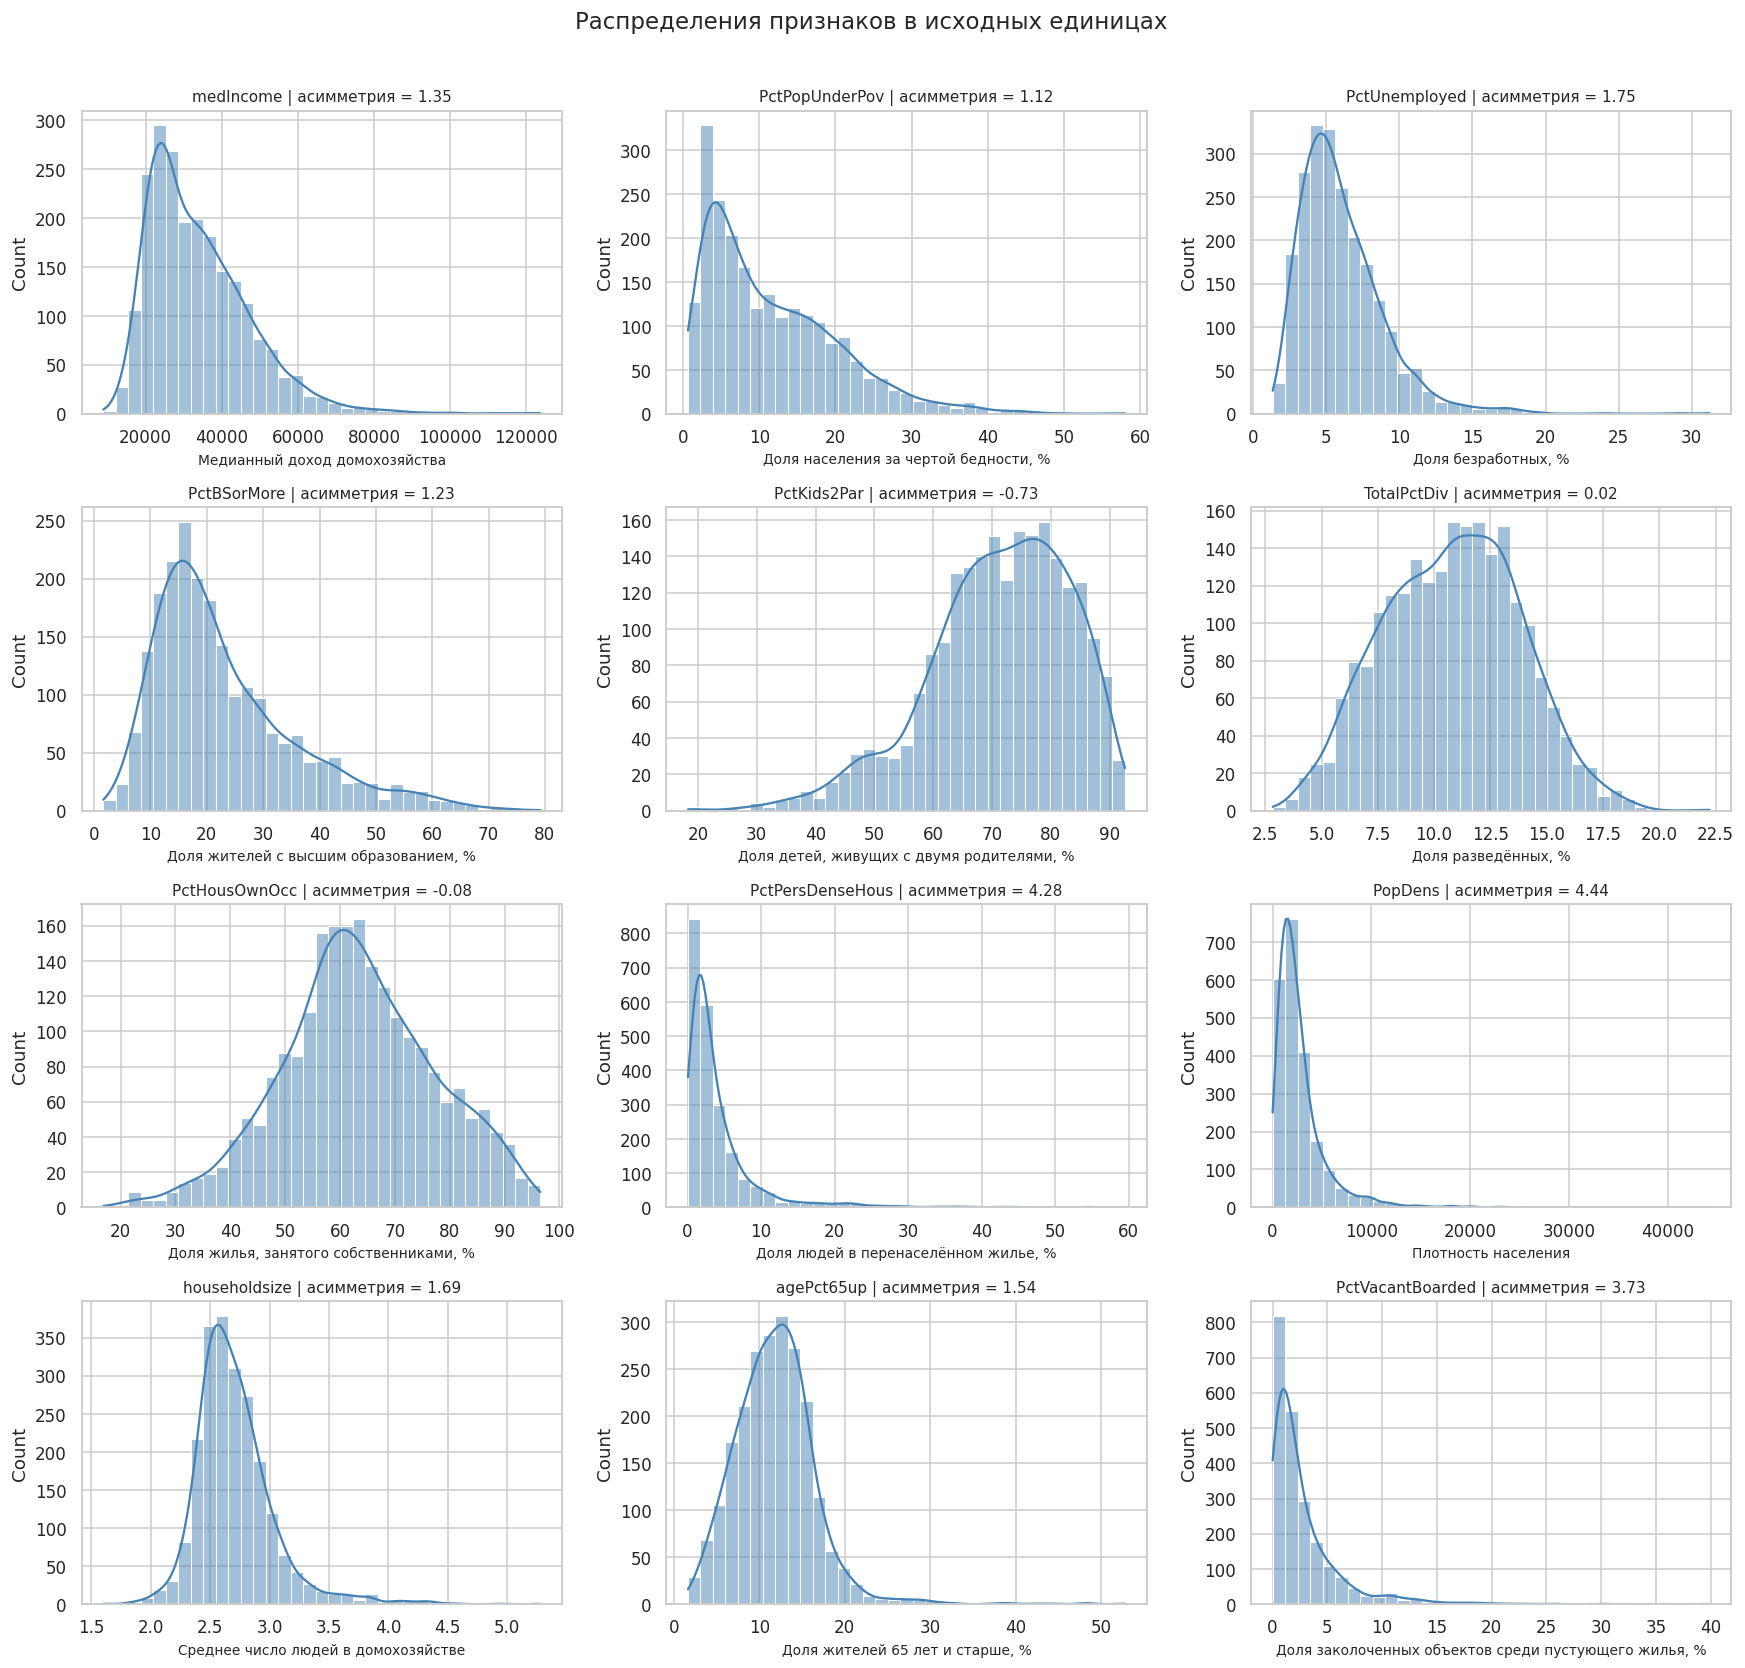

,За границами 1.5 IQR
medIncome,43
PctPopUnderPov,37
PctUnemployed,65
PctBSorMore,97
PctKids2Par,31
TotalPctDiv,1
PctHousOwnOcc,17
PctPersDenseHous,178
PopDens,156
householdsize,93


Объектов за границами 1.5 IQR хотя бы по одному признаку: 590


In [4]:
distribution_table = pd.DataFrame({
    'Асимметрия': X_imputed.skew(),
    'Эксцесс': X_imputed.kurt(),
    'p нормальности': [stats.normaltest(X_imputed[c]).pvalue for c in selected_features],
}, index=selected_features)
distribution_table['p < 0.05'] = distribution_table['p нормальности'] < 0.05
display(distribution_table)

fig, axes = plt.subplots(4, 3, figsize=(16, 15))
for ax, feature in zip(axes.flat, selected_features):
    sns.histplot(X_imputed[feature], bins=35, kde=True, ax=ax, color='steelblue')
    ax.set_title(f'{feature} | асимметрия = {distribution_table.loc[feature, "Асимметрия"]:.2f}', fontsize=10)
    ax.set_xlabel(FEATURE_DESCRIPTIONS[feature], fontsize=9)
for ax in axes.flat[len(selected_features):]:
    ax.set_visible(False)
fig.suptitle('Распределения признаков в исходных единицах', y=1.01, fontsize=15)
plt.tight_layout()
plt.show()

# IQR 1.5 используется для диагностики: для асимметричных признаков это не перечень ошибок.
raw_q1, raw_q3 = X_imputed.quantile(0.25), X_imputed.quantile(0.75)
raw_iqr = raw_q3 - raw_q1
raw_outlier_flags = ((X_imputed < raw_q1 - 1.5 * raw_iqr)
                     | (X_imputed > raw_q3 + 1.5 * raw_iqr))
display(raw_outlier_flags.sum().rename('За границами 1.5 IQR').to_frame())
print('Объектов за границами 1.5 IQR хотя бы по одному признаку:',
      int(raw_outlier_flags.any(axis=1).sum()))

**Анализ результатов.**

По гистограммам TotalPctDiv и PctHousOwnOcc близки к симметричным колоколообразным распределениям, а доход, бедность, безработица, плотность населения и характеристики проблемного жилья имеют правые хвосты. У PctKids2Par хвост направлен влево. Симметрия сама по себе не подтверждает нормальность; результаты теста приведены в таблице выше.

По тесту нормальности гипотеза отвергается для 11 из 12 признаков. Для PctHousOwnOcc p ≈ 0.211, поэтому оснований отвергнуть нормальность на уровне 0.05 не получено. Это не доказывает нормальность. По исходным границам 1.5 IQR отмечено 590 объектов; их массовое удаление могло бы исключить содержательно важные населённые пункты.

**Подготовка к обработке хвостов.**

Сильно асимметричные неотрицательные признаки (skew > 1) преобразуем как log1p(x).
Это уменьшает влияние длинных правых хвостов и допускает нули. Затем фиксируем для каждого
преобразованного признака внешние границы Тьюки Q1 − 3·IQR и Q3 + 3·IQR.
Основной анализ проводится без объектов, выходящих хотя бы за одну из этих границ.

Это явное операционное определение экстремальных наблюдений, а не доказательство наличия
ошибок в данных. Границы рассчитываются один раз и не пересчитываются после удаления.
В конце проверяется чувствительность результата к возвращению всех объектов.

Признаки с log1p: medIncome, PctPopUnderPov, PctUnemployed, PctBSorMore, PctPersDenseHous, PopDens, householdsize, agePct65up, PctVacantBoarded
Исключено экстремальных наблюдений: 18 (0.81%); осталось 2197.


,Асимметрия до log1p,Асимметрия после log1p,За границами 3 IQR
medIncome,1.348,0.226,0
PctPopUnderPov,1.115,-0.111,0
PctUnemployed,1.751,0.247,0
PctBSorMore,1.233,-0.030,0
PctKids2Par,-0.730,-0.730,0
TotalPctDiv,0.017,0.017,0
PctHousOwnOcc,-0.076,-0.076,0
PctPersDenseHous,4.275,0.938,0
PopDens,4.441,-0.254,2
householdsize,1.695,1.092,16


Примеры исключённых объектов:


,communityname,State,medIncome,PctPopUnderPov,PctUnemployed,PctBSorMore,PctKids2Par,TotalPctDiv,PctHousOwnOcc,PctPersDenseHous,PopDens,householdsize,agePct65up,PctVacantBoarded
37,Norcocity,CA,51594,5.34,5.10,10.32,75.36,9.94,82.40,6.06,1641.4,4.17,4.44,3.63
93,SouthJordancity,UT,43804,3.21,3.21,22.85,91.50,4.10,91.06,4.84,585.8,4.32,3.71,7.14
385,Harvardtown,MA,47299,3.88,1.66,42.39,91.11,5.49,46.79,3.29,451.5,4.14,2.43,0.61
706,WestHollywoodcity,CA,29314,11.43,7.04,37.43,66.33,15.57,22.28,4.88,18541.1,1.60,15.91,0.88
719,Rexburgcity,ID,19183,41.77,8.70,19.93,85.57,2.83,40.43,21.71,3247.5,4.18,4.21,1.47
755,Maywoodcity,CA,25567,21.26,12.22,1.63,65.51,7.89,30.53,59.01,23054.6,4.29,3.97,6.52
1136,Corcorancity,CA,21558,24.15,12.35,5.43,63.50,8.44,55.94,18.40,2277.4,5.28,4.53,1.66
1168,Oronotown,ME,27922,21.14,4.86,50.88,69.72,4.68,50.59,3.06,560.5,4.31,5.89,0.43
1244,SouthElMontecity,CA,27074,21.19,11.49,3.54,61.45,8.95,49.04,44.16,6959.3,4.37,5.09,5.38
1246,Cudahycity,CA,22279,27.54,10.24,2.82,59.29,10.66,16.86,54.34,20014.9,4.34,3.73,2.58


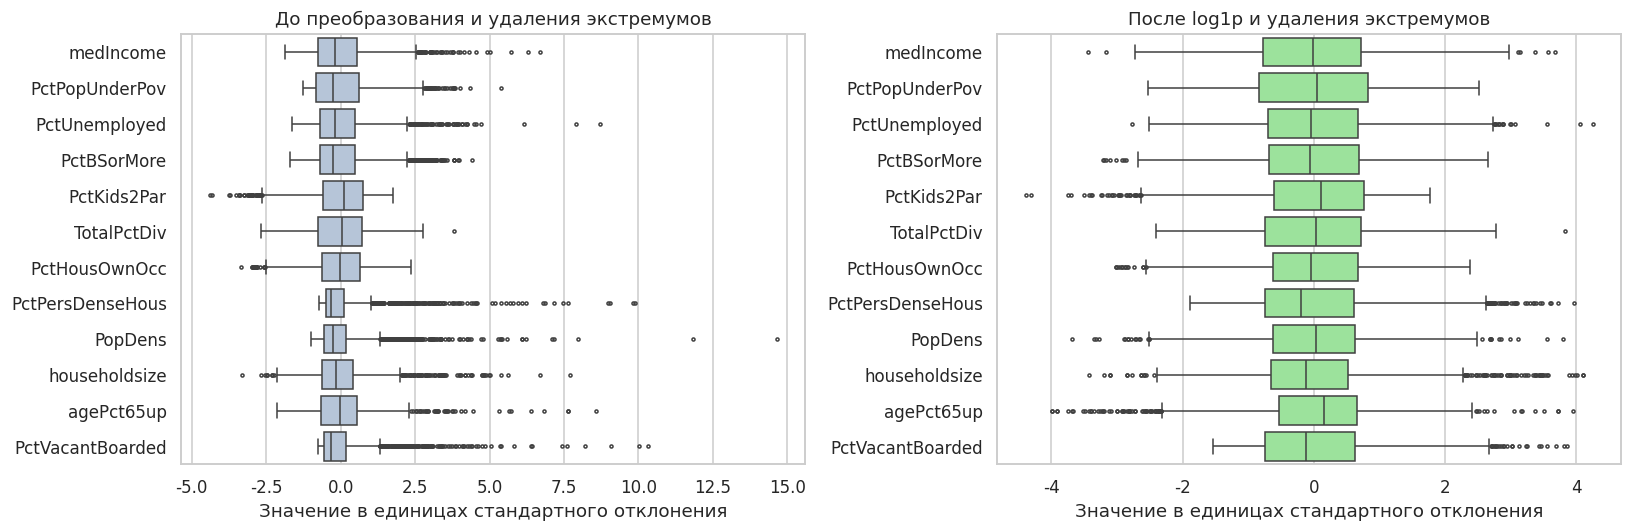

In [5]:
log_features = [feature for feature in selected_features
                if X_imputed[feature].min() >= 0 and X_imputed[feature].skew() > 1]
X_transformed_all = X_imputed.copy()
X_transformed_all[log_features] = np.log1p(X_transformed_all[log_features])
q1, q3 = X_transformed_all.quantile(0.25), X_transformed_all.quantile(0.75)
iqr = q3 - q1
lower_bounds, upper_bounds = q1 - 3 * iqr, q3 + 3 * iqr
extreme_flags = ((X_transformed_all < lower_bounds) | (X_transformed_all > upper_bounds))
inlier_mask = ~extreme_flags.any(axis=1)
X_transformed = X_transformed_all.loc[inlier_mask].copy()
analysis_index = X_transformed.index
print('Признаки с log1p:', ', '.join(log_features))
print(f'Исключено экстремальных наблюдений: {(~inlier_mask).sum()} '
      f'({(~inlier_mask).mean():.2%}); осталось {len(analysis_index)}.')
display(pd.DataFrame({
    'Асимметрия до log1p': X_imputed.skew(),
    'Асимметрия после log1p': X_transformed_all.skew(),
    'За границами 3 IQR': extreme_flags.sum(),
}).round(3))
assert not ((X_transformed < lower_bounds) | (X_transformed > upper_bounds)).any().any()

extreme_examples = df.loc[~inlier_mask, ['communityname', 'State'] + selected_features]
if len(extreme_examples):
    print('Примеры исключённых объектов:')
    display(extreme_examples.head(10))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
before_plot = (X_imputed - X_imputed.mean()) / X_imputed.std(ddof=0)
after_plot = (X_transformed - X_transformed.mean()) / X_transformed.std(ddof=0)
sns.boxplot(data=before_plot, orient='h', ax=axes[0], color='lightsteelblue', fliersize=2)
sns.boxplot(data=after_plot, orient='h', ax=axes[1], color='lightgreen', fliersize=2)
axes[0].set_title('До преобразования и удаления экстремумов')
axes[1].set_title('После log1p и удаления экстремумов')
for ax in axes:
    ax.set_xlabel('Значение в единицах стандартного отклонения')
plt.tight_layout()
plt.show()

Преобразование log1p применено к девяти признакам с правой асимметрией. По зафиксированным границам 3 IQR исключено 18 объектов (0.81%); для основного анализа осталось 2197 объектов. Это значительно меньше 590 объектов, отмеченных исходным диагностическим правилом 1.5 IQR. Такой подход сохраняет основную часть разнообразия населённых пунктов. Оставшиеся данные не содержат пропусков и выходов за выбранные границы, однако отсутствие всех возможных многомерных аномалий этим не доказано.

Проверка применимости. Объекты сопоставимы по смыслу: это населённые пункты; фиксированных классов в пространстве признаков нет. Выбрано 12 числовых неконстантных признаков; максимальная парная корреляция в исходных единицах по модулю — 0.773. После подготовки остаётся 2197 объектов, без пропусков и выходов за зафиксированные границы 3 IQR. Это не исключает многомерных аномалий. Существование хорошо разделённых естественных групп пока не установлено: его оцениваем по визуализациям, внутренним метрикам и устойчивости.

## 4. Стандартизация и матрица диаграмм рассеивания

Используется StandardScaler: z = (x − среднее) / стандартное отклонение.
После обработки хвостов признаки получают единичную дисперсию, поэтому доход или плотность
не определяют евклидово расстояние только за счёт единиц измерения. MinMaxScaler сильнее
зависел бы от крайних значений и не обеспечивал бы одинаковую дисперсию.
Стандартизация не делает распределения нормальными.

Train/test-разбиение здесь не требуется: задача — описательная кластеризация имеющейся выборки.
PCA и масштабирование оцениваются по анализируемым объектам; обобщение на новые города
этим экспериментом не проверяется.

Проверка порога корреляции 0.85 на этапе отбора относится к исходным единицам. После log1p связь дохода и бедности усиливается (на полной выборке r ≈ −0.91). Оба показателя сохранены как разные содержательные характеристики, но их совместное использование повышает вес уровня обеспеченности в расстояниях. Это ограничение выбранного пространства признаков, а не свидетельство независимости всех его координат.

,Среднее после стандартизации,Стандартное отклонение (ddof=0)
medIncome,-0.0,1.0
PctPopUnderPov,-0.0,1.0
PctUnemployed,0.0,1.0
PctBSorMore,-0.0,1.0
PctKids2Par,-0.0,1.0
TotalPctDiv,0.0,1.0
PctHousOwnOcc,0.0,1.0
PctPersDenseHous,0.0,1.0
PopDens,-0.0,1.0
householdsize,-0.0,1.0


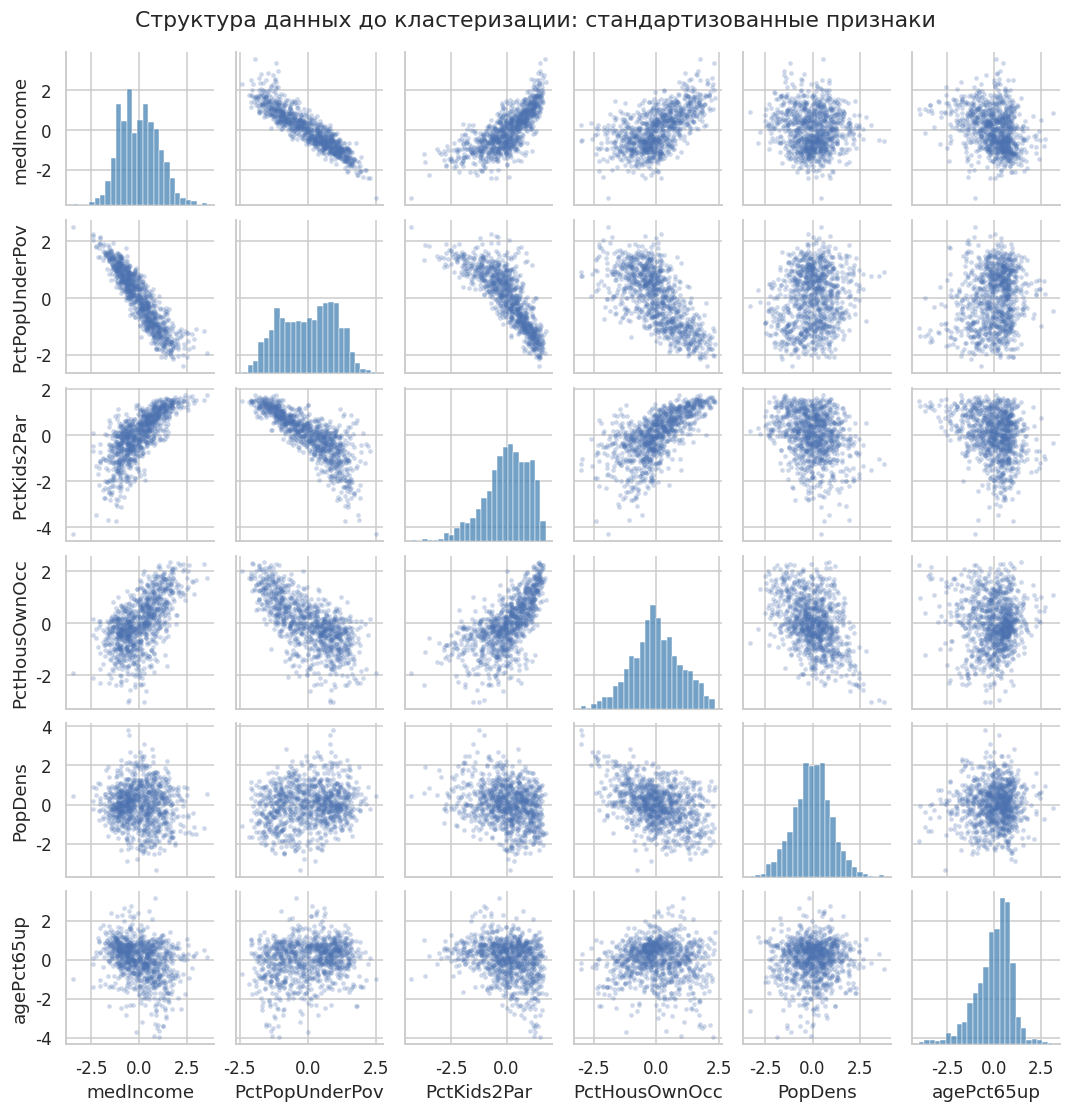

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_transformed)
X_scaled_df = pd.DataFrame(X_scaled, columns=selected_features, index=analysis_index)
assert np.isfinite(X_scaled).all()
display(pd.DataFrame({
    'Среднее после стандартизации': X_scaled.mean(axis=0),
    'Стандартное отклонение (ddof=0)': X_scaled.std(axis=0),
}, index=selected_features).round(6))

pair_features = ['medIncome', 'PctPopUnderPov', 'PctKids2Par',
                 'PctHousOwnOcc', 'PopDens', 'agePct65up']
pair_data = X_scaled_df[pair_features].sample(n=min(1000, len(X_scaled_df)), random_state=RANDOM_STATE)
grid = sns.pairplot(pair_data, diag_kind='hist', height=1.65,
                    plot_kws={'s': 9, 'alpha': 0.28, 'linewidth': 0},
                    diag_kws={'bins': 25, 'color': 'steelblue'})
grid.fig.suptitle('Структура данных до кластеризации: стандартизованные признаки', y=1.02)
plt.show()

На матрице рассеивания видны протяжённые взаимосвязанные облака: доход обратно связан с бедностью, а доля детей с двумя родителями положительно связана с долей жилья собственников. Чётких пустых промежутков между группами не видно; по возрасту и плотности населения разброс неоднороден. Проекции на две координаты не позволяют надёжно определить число групп в 12 измерениях.
Рабочая гипотеза — несколько крупных социально-экономических профилей с пересекающимися
границами; проверяем k = 2, …, 10, без заранее заданного «правильного» числа кластеров.

Выбор методов. K-means ищет компактные группы вокруг центров и служит базовым методом
для числовых стандартизованных признаков. Метод Уорда последовательно объединяет группы
с минимальным приростом внутрикластерной суммы квадратов и позволяет увидеть вложенную
структуру на дендрограмме. Оба метода ориентированы на компактные группы, поэтому их
пригодность нужно подтвердить метриками; при сильном перекрытии высокая оценка не ожидается.
Плотности и размеры групп могут различаться — это проверяется по размерам, радиусам и силуэтам.
DBSCAN не выбран: единый радиус соседства в многомерном пространстве при различной плотности
групп требует отдельного исследования.

## 5. Подбор количества кластеров: локоть, силуэт и дендрограмма

Для обоих методов вычисляются Silhouette, Calinski–Harabasz (CH), Davies–Bouldin (DB)
и внутрикластерная сумма квадратов (SSE). Основной заранее заданный критерий выбора k —
максимум среднего силуэта в диапазоне 2–10. CH и DB служат дополнительными проверками.
Для K-means также строится график локтя; его численная подсказка — максимальное отклонение
нормированной кривой SSE от хорды между крайними точками. Это эвристика, а не доказательство
истинного количества групп. Для иерархического метода строится дендрограмма.

Все метрики рассчитываются на одной и той же полной подготовленной выборке в исходном
многомерном стандартизованном пространстве, а не на двумерной PCA-проекции.

,Метод,k,Silhouette,Calinski–Harabasz,Davies–Bouldin,SSE,Минимальный кластер,Максимальный кластер
0,K-means,2,0.2765,1053.0766,1.3571,17816.3838,988,1209
1,Ward,2,0.2256,748.5448,1.4511,19659.6230,668,1529
2,K-means,3,0.1833,767.4242,1.7171,15512.1930,634,872
3,Ward,3,0.1445,619.8960,1.8885,16845.1132,659,870
4,K-means,4,0.1844,642.8584,1.6138,14027.7077,275,748
5,Ward,4,0.1315,502.3730,1.9186,15625.5109,275,668
6,K-means,5,0.1566,554.9797,1.7256,13098.5840,246,546
7,Ward,5,0.1248,430.7612,1.9004,14760.9779,135,659
8,K-means,6,0.1556,497.5818,1.7991,12345.5113,196,506
9,Ward,6,0.1044,387.9414,1.9787,13983.9309,135,595


Выбранное k по силуэту: {'K-means': 2, 'Ward': 2}
Подсказка метода локтя для K-means: 3


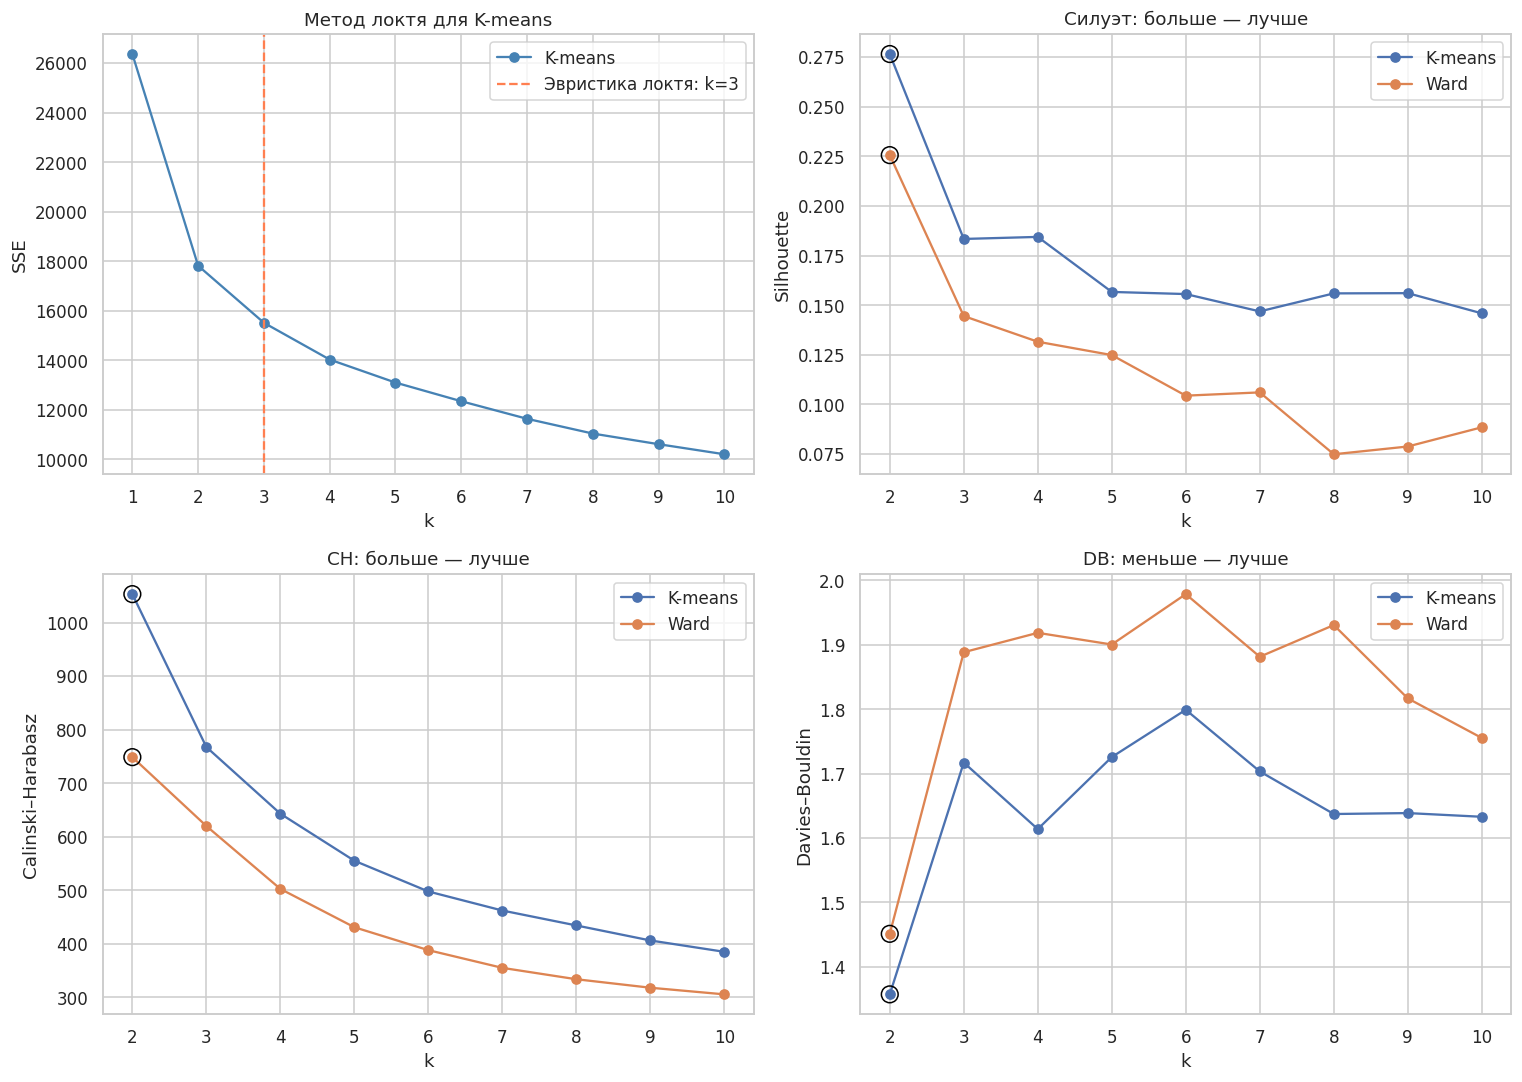

In [7]:
K_VALUES = list(range(2, 11))
METHODS = ['K-means', 'Ward']
distance_matrix = pairwise_distances(X_scaled, metric='euclidean')
np.fill_diagonal(distance_matrix, 0.0)

def centroids_for_labels(values, labels):
    return np.vstack([values[labels == cluster].mean(axis=0) for cluster in np.unique(labels)])

def within_sse(values, labels):
    return sum(np.square(values[labels == cluster] - values[labels == cluster].mean(axis=0)).sum()
               for cluster in np.unique(labels))

def internal_scores(values, labels, distances=None):
    silhouette = (silhouette_score(distances, labels, metric='precomputed')
                  if distances is not None else silhouette_score(values, labels))
    return {
        'Silhouette': silhouette,
        'Calinski–Harabasz': calinski_harabasz_score(values, labels),
        'Davies–Bouldin': davies_bouldin_score(values, labels),
        'SSE': within_sse(values, labels),
    }

hierarchy = linkage(X_scaled, method='ward', metric='euclidean')
ward_cuts = cut_tree(hierarchy, n_clusters=K_VALUES)
kmeans_candidates, ward_labels_by_k = {}, {}
search_rows = []
for column, k in enumerate(K_VALUES):
    model = KMeans(n_clusters=k, init='k-means++', n_init=10,
                   random_state=RANDOM_STATE, max_iter=500)
    km_labels = model.fit_predict(X_scaled)
    kmeans_candidates[k] = model
    ward_labels_by_k[k] = ward_cuts[:, column]
    for method, labels in [('K-means', km_labels), ('Ward', ward_cuts[:, column])]:
        sizes = np.bincount(labels)
        search_rows.append({
            'Метод': method, 'k': k,
            **internal_scores(X_scaled, labels, distance_matrix),
            'Минимальный кластер': sizes.min(), 'Максимальный кластер': sizes.max(),
        })
search_results = pd.DataFrame(search_rows)
best_k = {
    method: int(search_results.loc[
        search_results.loc[search_results['Метод'] == method, 'Silhouette'].idxmax(), 'k'])
    for method in METHODS
}

km_search = search_results[search_results['Метод'] == 'K-means'].sort_values('k')
elbow_k_values = np.array([1] + K_VALUES)
elbow_sse = np.array([within_sse(X_scaled, np.zeros(len(X_scaled), dtype=int))]
                     + km_search['SSE'].tolist())
elbow_x = (elbow_k_values - elbow_k_values.min()) / np.ptp(elbow_k_values)
elbow_y = (elbow_sse - elbow_sse.min()) / np.ptp(elbow_sse)
elbow_distances = (1 - elbow_x) - elbow_y
elbow_k = int(elbow_k_values[np.argmax(elbow_distances)])
display(search_results.round(4))
print('Выбранное k по силуэту:', best_k)
print('Подсказка метода локтя для K-means:', elbow_k)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].plot(elbow_k_values, elbow_sse, 'o-', color='steelblue', label='K-means')
axes[0, 0].axvline(elbow_k, color='coral', linestyle='--', label=f'Эвристика локтя: k={elbow_k}')
axes[0, 0].set(title='Метод локтя для K-means', xlabel='k', ylabel='SSE')
axes[0, 0].legend()
for ax, metric, title in zip(axes.flat[1:],
                             ['Silhouette', 'Calinski–Harabasz', 'Davies–Bouldin'],
                             ['Силуэт: больше — лучше', 'CH: больше — лучше', 'DB: меньше — лучше']):
    for method in METHODS:
        values = search_results[search_results['Метод'] == method]
        ax.plot(values['k'], values[metric], 'o-', label=method)
        chosen = values[values['k'] == best_k[method]].iloc[0]
        ax.scatter(chosen['k'], chosen[metric], s=120, facecolors='none', edgecolors='black', zorder=5)
    ax.set(title=title, xlabel='k', ylabel=metric)
    ax.legend()
for ax in axes.flat:
    ax.set_xticks(elbow_k_values if ax == axes[0, 0] else K_VALUES)
plt.tight_layout()
plt.show()

Максимум силуэта в диапазоне 2–10 достигнут при k=2 для обоих методов: 0.277 у K-means и 0.226 у Уорда. При увеличении числа групп средний силуэт становится ниже. Численная подсказка локтя K-means даёт k=3, то есть предлагает более подробный уровень описания. В соответствии с заранее выбранным основным критерием сохраняем k=2; преступность при этом выборе не использовалась.

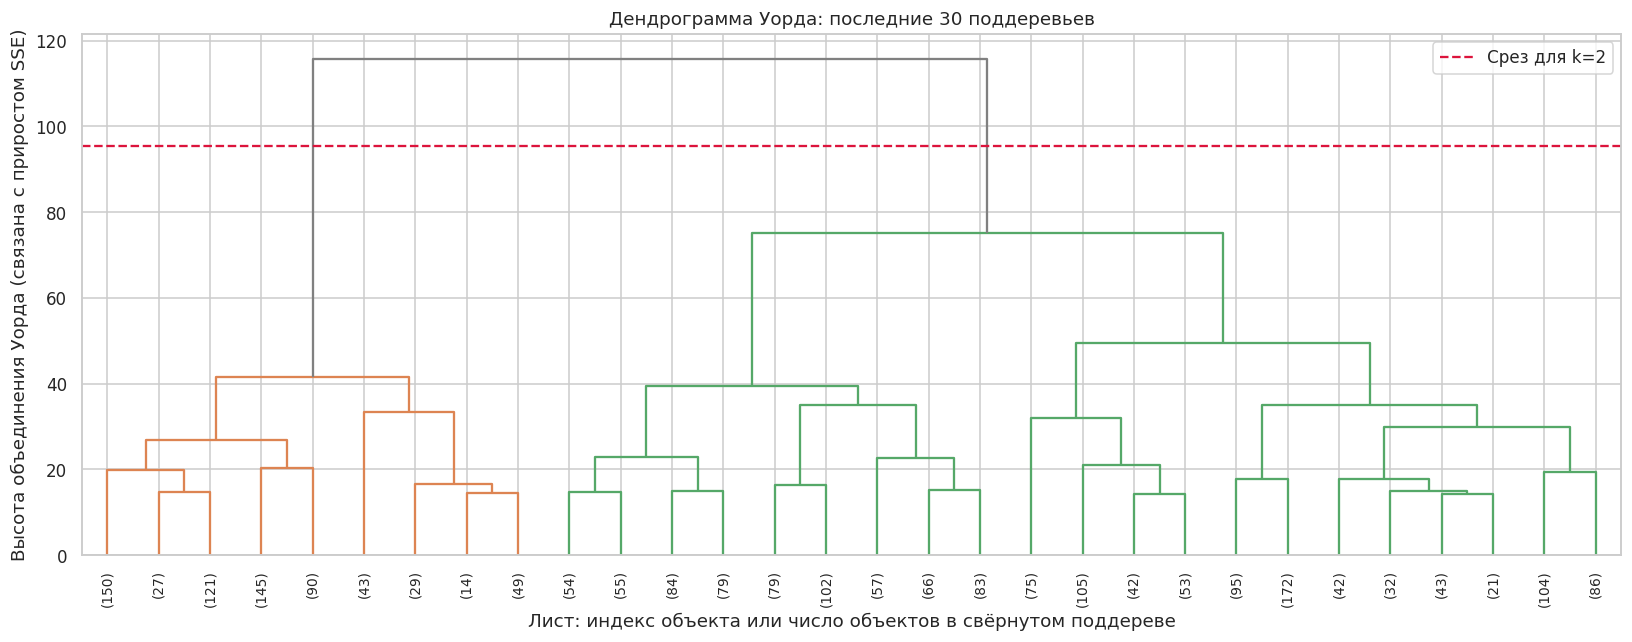

In [8]:
ward_k = best_k['Ward']
cut_height = (hierarchy[-(ward_k - 1), 2] + hierarchy[-ward_k, 2]) / 2
fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(hierarchy, truncate_mode='lastp', p=30, show_leaf_counts=True,
           color_threshold=cut_height, above_threshold_color='gray',
           leaf_rotation=90, leaf_font_size=9, ax=ax)
ax.axhline(cut_height, color='crimson', linestyle='--', label=f'Срез для k={ward_k}')
ax.set(title='Дендрограмма Уорда: последние 30 поддеревьев',
       xlabel='Лист: индекс объекта или число объектов в свёрнутом поддереве',
       ylabel='Высота объединения Уорда (связана с приростом SSE)')
ax.legend()
plt.tight_layout()
plt.show()

На дендрограмме последний крупный шаг объединения расположен заметно выше предыдущего. Проведённый между ними горизонтальный срез даёт две группы и согласуется с максимумом силуэта. Это поддерживает выбор двух крупных профилей, но не доказывает существование единственного правильного числа естественных классов. Свёрнутые листья обозначают поддеревья, а не отдельные исходные наблюдения.

## 6. Итоговые модели и внутренние метрики качества

Для K-means используется n_init=10. Итоговая иерархическая модель обучается через
AgglomerativeClustering(linkage='ward'); её разбиение сверяется с разрезом дерева SciPy.

Silhouette лежит в диапазоне от −1 до 1: высокие значения означают компактные и разделённые
группы; значения около нуля — близость к границе; отрицательные — возможное неверное назначение.
Для CH предпочтительнее большее значение, для DB — меньшее.
Эти критерии сравниваются при одинаковых данных и пространстве расстояний.

ARI между итоговым Ward и выбранным срезом SciPy: 1.000000


,k,Silhouette,Calinski–Harabasz,Davies–Bouldin,SSE,Доля отрицательных силуэтов,Минимальный кластер,Максимальный кластер
Метод,,,,,,,,
K-means,2,0.2765,1053.0766,1.3571,17816.3838,0.0114,988,1209
Ward,2,0.2256,748.5448,1.4511,19659.6230,0.1397,668,1529


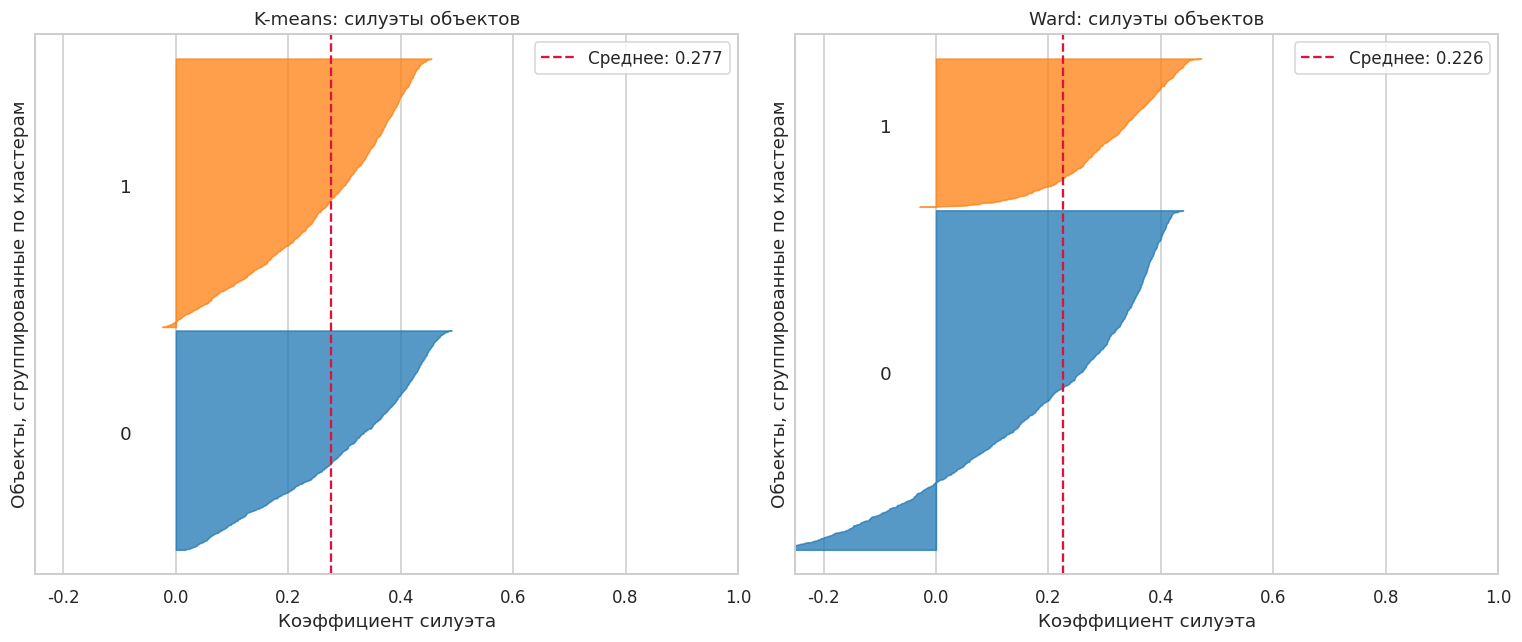

In [9]:
kmeans_model = kmeans_candidates[best_k['K-means']]
ward_model = AgglomerativeClustering(n_clusters=best_k['Ward'], linkage='ward')
labels_by_method = {
    'K-means': kmeans_model.labels_.copy(),
    'Ward': ward_model.fit_predict(X_scaled),
}
tree_agreement = adjusted_rand_score(ward_labels_by_k[best_k['Ward']], labels_by_method['Ward'])
print(f'ARI между итоговым Ward и выбранным срезом SciPy: {tree_agreement:.6f}')
assert np.isclose(tree_agreement, 1.0), 'Разрезы дерева различаются; необходимо перепроверить подбор k.'

silhouette_values = {}
quality_rows = []
for method, labels in labels_by_method.items():
    silhouette_values[method] = silhouette_samples(distance_matrix, labels, metric='precomputed')
    sizes = np.bincount(labels)
    quality_rows.append({
        'Метод': method, 'k': len(sizes), **internal_scores(X_scaled, labels, distance_matrix),
        'Доля отрицательных силуэтов': np.mean(silhouette_values[method] < 0),
        'Минимальный кластер': sizes.min(), 'Максимальный кластер': sizes.max(),
    })
quality = pd.DataFrame(quality_rows).set_index('Метод')
display(quality.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, method in zip(axes, METHODS):
    labels = labels_by_method[method]
    scores = silhouette_values[method]
    y_lower = 10
    for cluster in np.unique(labels):
        ordered = np.sort(scores[labels == cluster])
        y_upper = y_lower + len(ordered)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ordered,
                         alpha=0.75, color=sns.color_palette('tab10')[cluster % 10])
        ax.text(-0.10, y_lower + len(ordered) / 2, str(cluster))
        y_lower = y_upper + 15
    ax.axvline(scores.mean(), color='crimson', linestyle='--', label=f'Среднее: {scores.mean():.3f}')
    ax.set(title=f'{method}: силуэты объектов', xlabel='Коэффициент силуэта',
           ylabel='Объекты, сгруппированные по кластерам', xlim=(-0.25, 1))
    ax.set_yticks([])
    ax.legend()
plt.tight_layout()
plt.show()

**K-means:** Silhouette=0.277; разделение умеренное. Доля отрицательных силуэтов — 1.1%. Границы 0.25 и 0.5 используются только как ориентиры для описания, а не как строгий тест.

**Ward:** Silhouette=0.226; группы сильно перекрываются. Доля отрицательных силуэтов — 14.0%. Границы 0.25 и 0.5 используются только как ориентиры для описания, а не как строгий тест.

## 7. Центры, компактность и расстояния между кластерами

Центр определяется как среднее в стандартизованном пространстве.
Средний радиус — среднее расстояние объекта до своего центра; **RMS-радиус** —
корень из среднего квадрата этого расстояния. Дополнительно вычисляются средние попарные
расстояния внутри групп, SSE и 90-й процентиль радиуса.

Между каждой парой групп рассчитываются расстояние центров, минимальное расстояние между
объектами (single linkage), максимальное (complete linkage) и среднее попарное расстояние.
Отношение расстояния центров к сумме RMS-радиусов — описательный показатель перекрытия:
небольшие значения указывают на близость групп относительно их разброса, но не являются
строгим критерием разделимости.

,Метод,Кластер,Размер,Доля,Средний радиус,RMS-радиус,Радиус p90,Среднее попарное внутри,SSE
0,K-means,0,988,0.450,2.633,2.754,3.689,3.722,7492.761
1,K-means,1,1209,0.550,2.748,2.922,4.056,3.911,10323.622
2,Ward,0,1529,0.696,2.946,3.091,4.225,4.161,14609.303
3,Ward,1,668,0.304,2.564,2.750,3.927,3.656,5050.320


,Метод,Пара кластеров,Между центрами,Минимальное между объектами,Среднее между объектами,Максимальное между объектами,Центры / сумма RMS-радиусов
0,K-means,0–1,3.965,0.549,5.404,15.832,0.699
1,Ward,0–1,3.798,0.844,5.338,15.832,0.650


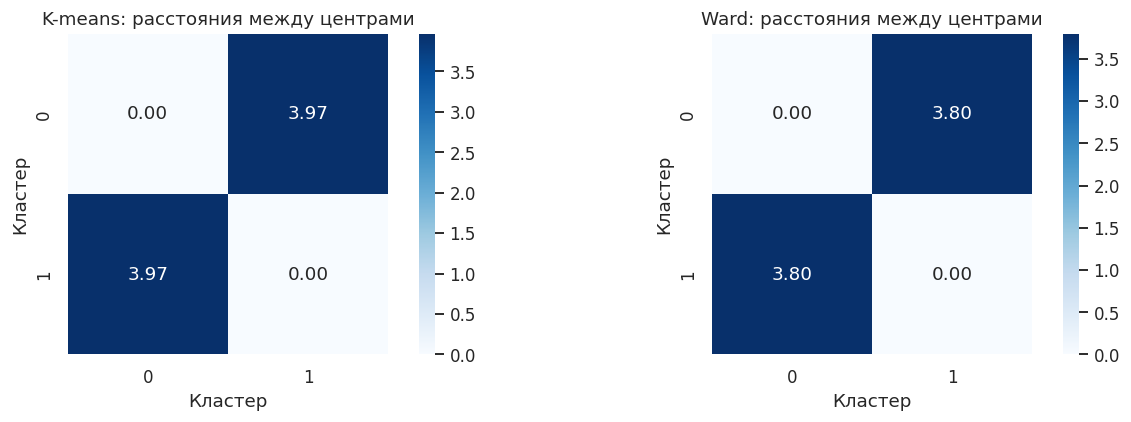

In [10]:
cluster_geometry_rows, between_rows = [], []
centers_scaled, centers_original = {}, {}
for method, labels in labels_by_method.items():
    clusters = np.unique(labels)
    centers = centroids_for_labels(X_scaled, labels)
    centers_scaled[method] = pd.DataFrame(centers, columns=selected_features,
                                         index=pd.Index(clusters, name='Кластер'))
    center_transformed = pd.DataFrame(scaler.inverse_transform(centers),
                                      columns=selected_features, index=clusters)
    center_transformed[log_features] = np.expm1(center_transformed[log_features])
    centers_original[method] = center_transformed
    rms_radii = {}
    for cluster in clusters:
        points = X_scaled[labels == cluster]
        radii = np.linalg.norm(points - centers[cluster], axis=1)
        rms_radii[cluster] = np.sqrt(np.mean(radii ** 2))
        within_distances = pdist(points, metric='euclidean')
        cluster_geometry_rows.append({
            'Метод': method, 'Кластер': cluster, 'Размер': len(points),
            'Доля': len(points) / len(X_scaled), 'Средний радиус': radii.mean(),
            'RMS-радиус': rms_radii[cluster], 'Радиус p90': np.quantile(radii, 0.9),
            'Среднее попарное внутри': within_distances.mean() if len(within_distances) else 0.0,
            'SSE': np.sum(radii ** 2),
        })
    for position, first in enumerate(clusters):
        for second in clusters[position + 1:]:
            distances = cdist(X_scaled[labels == first], X_scaled[labels == second])
            center_distance = np.linalg.norm(centers[first] - centers[second])
            between_rows.append({
                'Метод': method, 'Пара кластеров': f'{first}–{second}',
                'Между центрами': center_distance, 'Минимальное между объектами': distances.min(),
                'Среднее между объектами': distances.mean(), 'Максимальное между объектами': distances.max(),
                'Центры / сумма RMS-радиусов': center_distance / (rms_radii[first] + rms_radii[second]),
            })
cluster_geometry = pd.DataFrame(cluster_geometry_rows)
between_geometry = pd.DataFrame(between_rows)
display(cluster_geometry.round(3))
display(between_geometry.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, method in zip(axes, METHODS):
    center_distances = cdist(centers_scaled[method], centers_scaled[method])
    sns.heatmap(center_distances, annot=True, fmt='.2f', cmap='Blues', square=True, ax=ax,
                xticklabels=centers_scaled[method].index, yticklabels=centers_scaled[method].index)
    ax.set(title=f'{method}: расстояния между центрами', xlabel='Кластер', ylabel='Кластер')
plt.tight_layout()
plt.show()

**K-means:** наиболее компактна группа 0 (RMS-радиус 2.75), наиболее рассеяна группа 1 (RMS-радиус 2.92). Среднее расстояние внутри групп, взвешенное по числу пар, — 3.84; минимальное расстояние между центрами — 3.97. Минимальное расстояние между объектами разных групп — 0.55: оно описывает близость границ, а расстояние центров — различие типичных профилей.

**Ward:** наиболее компактна группа 1 (RMS-радиус 2.75), наиболее рассеяна группа 0 (RMS-радиус 3.09). Среднее расстояние внутри групп, взвешенное по числу пар, — 4.08; минимальное расстояние между центрами — 3.80. Минимальное расстояние между объектами разных групп — 0.84: оно описывает близость границ, а расстояние центров — различие типичных профилей.

## 8. PCA и визуализация полученных кластеров

PCA обучается один раз на той же стандартизованной матрице и используется для отображения
обоих разбиений. Алгоритмы кластеризации по-прежнему работают со всеми выбранными признаками.
Доля дисперсии первых двух компонент показывает, какую часть структуры отражает рисунок;
наложение групп на нём не означает их полного совпадения в многомерном пространстве.

Первые две компоненты объясняют 62.77% дисперсии.
Для сохранения 90% дисперсии требуется компонент: 6.


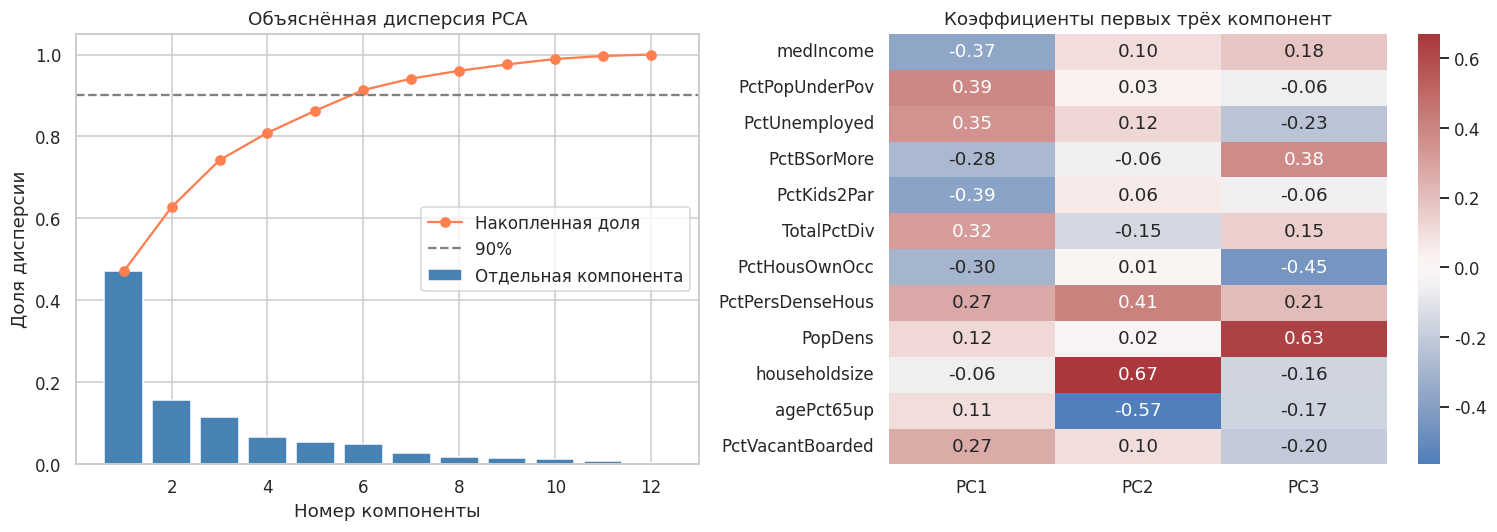

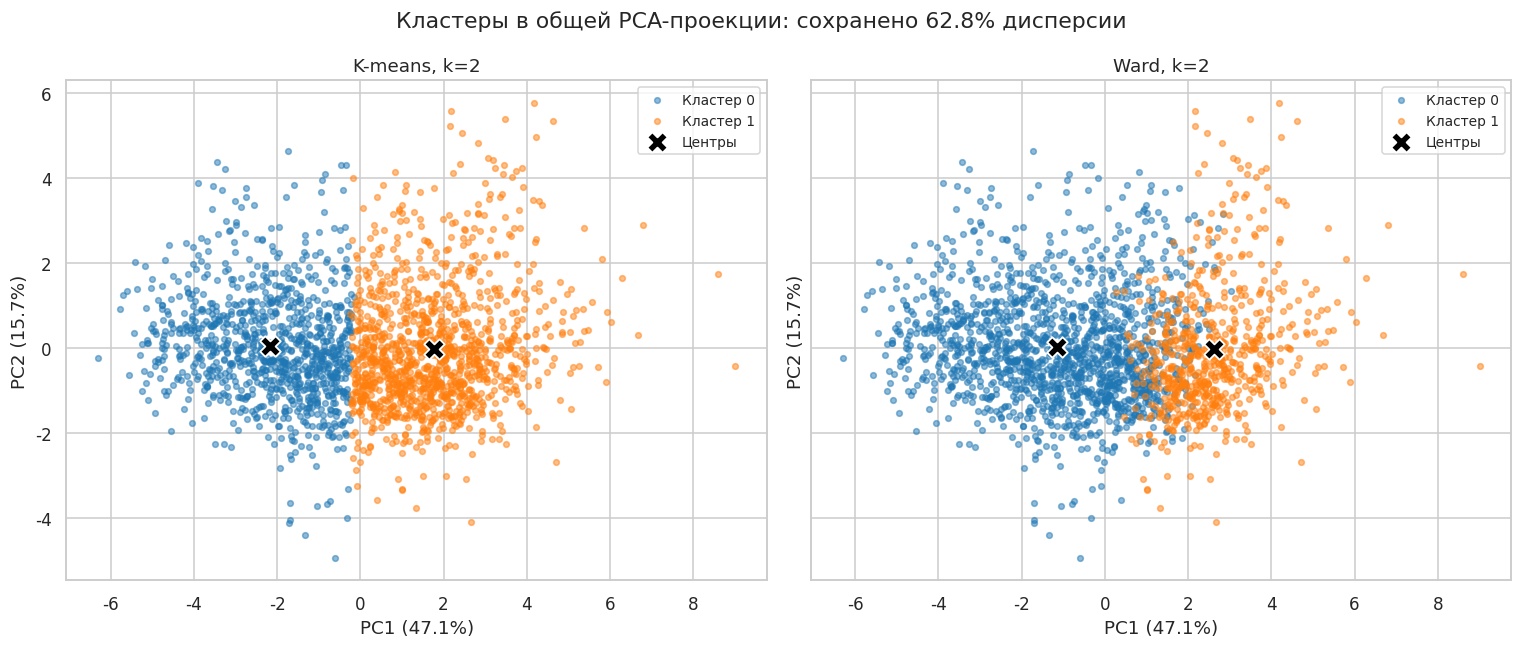

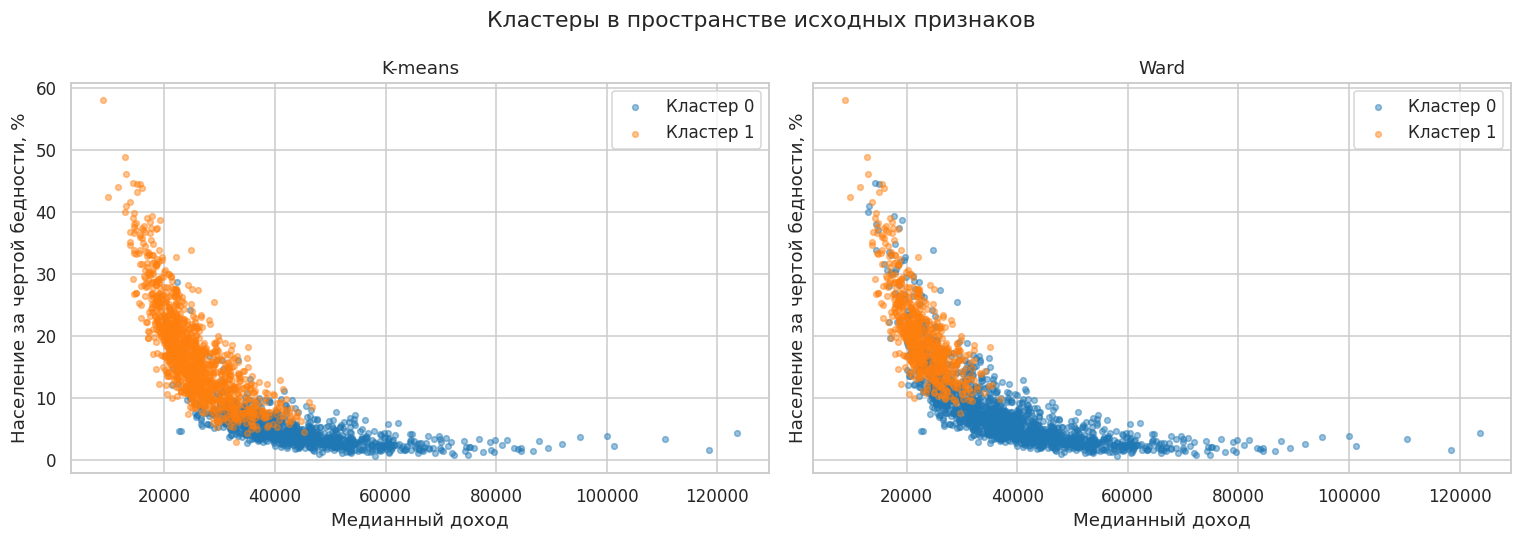

In [11]:
pca = PCA(svd_solver='full')
X_pca = pca.fit_transform(X_scaled)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
components_90 = int(np.searchsorted(cumulative_variance, 0.90) + 1)
print(f'Первые две компоненты объясняют {cumulative_variance[1]:.2%} дисперсии.')
print(f'Для сохранения 90% дисперсии требуется компонент: {components_90}.')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
component_numbers = np.arange(1, len(selected_features) + 1)
axes[0].bar(component_numbers, pca.explained_variance_ratio_, color='steelblue', label='Отдельная компонента')
axes[0].plot(component_numbers, cumulative_variance, 'o-', color='coral', label='Накопленная доля')
axes[0].axhline(0.9, color='gray', linestyle='--', label='90%')
axes[0].set(xlabel='Номер компоненты', ylabel='Доля дисперсии', title='Объяснённая дисперсия PCA')
axes[0].legend()
loadings = pd.DataFrame(pca.components_[:3].T, columns=['PC1', 'PC2', 'PC3'], index=selected_features)
sns.heatmap(loadings, annot=True, fmt='.2f', center=0, cmap='vlag', ax=axes[1])
axes[1].set_title('Коэффициенты первых трёх компонент')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, method in zip(axes, METHODS):
    labels = labels_by_method[method]
    for cluster in np.unique(labels):
        ax.scatter(X_pca[labels == cluster, 0], X_pca[labels == cluster, 1],
                   s=14, alpha=0.5, label=f'Кластер {cluster}',
                   color=sns.color_palette('tab10')[cluster % 10])
    projected_centers = pca.transform(centers_scaled[method].to_numpy())
    ax.scatter(projected_centers[:, 0], projected_centers[:, 1], marker='X',
               c='black', s=180, edgecolor='white', linewidth=1.2, label='Центры', zorder=5)
    ax.set(title=f'{method}, k={best_k[method]}',
           xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',
           ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
    ax.legend(fontsize=9)
fig.suptitle(f'Кластеры в общей PCA-проекции: сохранено {cumulative_variance[1]:.1%} дисперсии')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, method in zip(axes, METHODS):
    for cluster in np.unique(labels_by_method[method]):
        mask = labels_by_method[method] == cluster
        points = X_imputed.loc[analysis_index].iloc[np.flatnonzero(mask)]
        ax.scatter(points['medIncome'], points['PctPopUnderPov'], s=14, alpha=0.45,
                   label=f'Кластер {cluster}', color=sns.color_palette('tab10')[cluster % 10])
    ax.set(title=method, xlabel='Медианный доход', ylabel='Население за чертой бедности, %')
    ax.legend()
fig.suptitle('Кластеры в пространстве исходных признаков')
plt.tight_layout()
plt.show()

Первые две главные компоненты сохраняют 62.77% дисперсии (PC1 — около 47.1%, PC2 — около 15.7%). Для сохранения 90% требуются шесть компонент, поэтому двумерные рисунки отображают структуру лишь частично. По коэффициентам PC1 в основном отражает различия обеспеченности и семейно-жилищных характеристик, а PC2 — состава домохозяйств и возрастной структуры. На общей PCA-проекции группы соприкасаются и перекрываются, особенно у Уорда. На диаграмме доход–бедность различие профилей содержательно понятно, но непрерывный характер данных не позволяет считать границу между ними естественным разрывом.

## 9. Профили групп и содержательная интерпретация

Для каждой группы приведены:

- стандартизованный центр, отражающий отклонение от общей выборки;
- обратное преобразование центра в исходные единицы;
- обычные арифметические средние исходных признаков.

Для логарифмированных признаков обратный образ центра равен
exp(mean(log(1+x))) − 1, поэтому он не совпадает с арифметическим средним.
Содержательные выводы ниже опираются на средние в исходных единицах и стандартизованные профили.
Номера кластеров условны и между методами напрямую не сопоставляются.

K-means: центры и исходные средние
Центры после обратного преобразования:


,medIncome,PctPopUnderPov,PctUnemployed,PctBSorMore,PctKids2Par,TotalPctDiv,PctHousOwnOcc,PctPersDenseHous,PopDens,householdsize,agePct65up,PctVacantBoarded
0,42964.06,4.27,3.92,27.39,81.13,8.80,72.80,1.56,1637.91,2.73,9.92,0.95
1,24736.07,15.63,7.24,15.78,63.13,12.49,55.87,4.20,2306.49,2.65,12.05,2.95


Арифметические средние исходных признаков:


,medIncome,PctPopUnderPov,PctUnemployed,PctBSorMore,PctKids2Par,TotalPctDiv,PctHousOwnOcc,PctPersDenseHous,PopDens,householdsize,agePct65up,PctVacantBoarded
Кластер,,,,,,,,,,,,
0,44501.76,4.79,4.07,30.03,81.13,8.80,72.80,1.89,2240.56,2.74,10.91,1.25
1,25438.09,17.12,7.63,17.43,63.13,12.49,55.87,5.71,3170.35,2.66,12.68,4.02


Ward: центры и исходные средние
Центры после обратного преобразования:


,medIncome,PctPopUnderPov,PctUnemployed,PctBSorMore,PctKids2Par,TotalPctDiv,PctHousOwnOcc,PctPersDenseHous,PopDens,householdsize,agePct65up,PctVacantBoarded
0,36902.45,6.26,4.55,24.12,76.93,9.75,66.80,2.14,1836.49,2.70,10.31,1.21
1,22404.01,19.27,8.49,13.49,58.16,13.30,55.87,4.76,2342.06,2.65,12.92,4.27


Арифметические средние исходных признаков:


,medIncome,PctPopUnderPov,PctUnemployed,PctBSorMore,PctKids2Par,TotalPctDiv,PctHousOwnOcc,PctPersDenseHous,PopDens,householdsize,agePct65up,PctVacantBoarded
Кластер,,,,,,,,,,,,
0,38901.59,7.78,4.79,26.81,76.93,9.75,66.80,2.94,2556.61,2.71,11.19,1.57
1,22817.15,20.26,8.88,14.58,58.16,13.30,55.87,6.41,3199.96,2.67,13.47,5.54


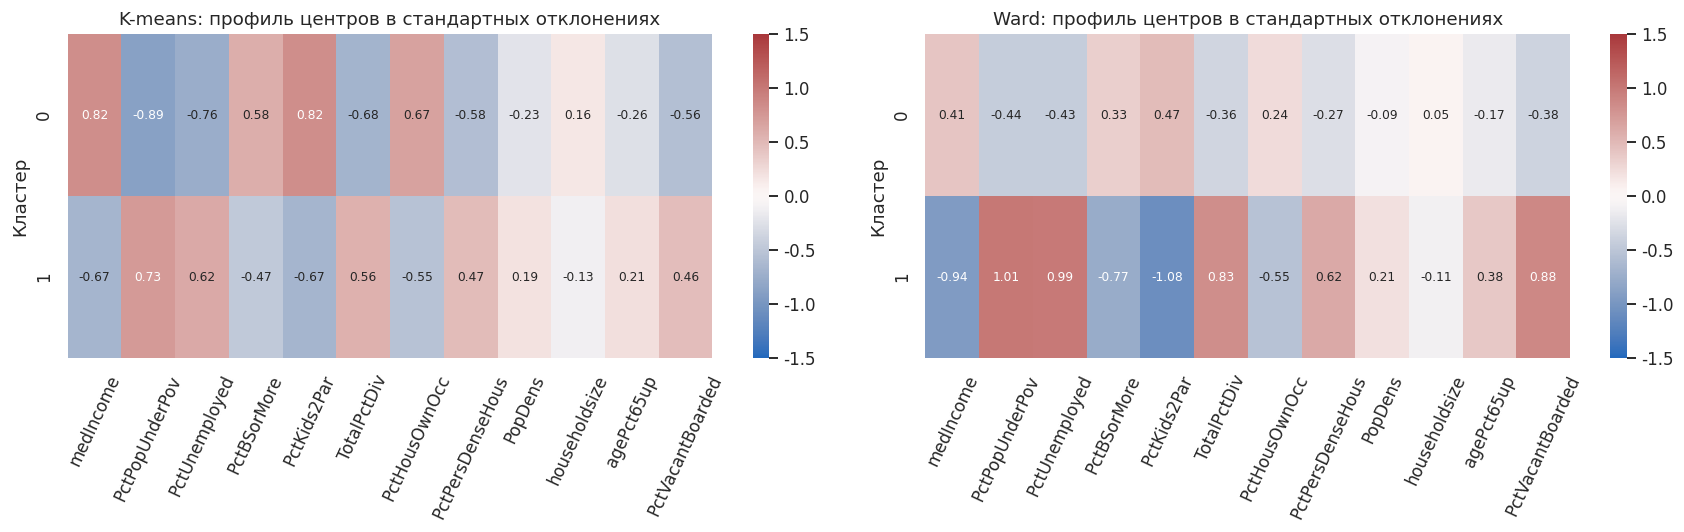

In [12]:
profile_means = {}
for method, labels in labels_by_method.items():
    original_profiles = X_imputed.loc[analysis_index].copy()
    original_profiles['Кластер'] = labels
    profile_means[method] = original_profiles.groupby('Кластер')[selected_features].mean()
    print(f'{method}: центры и исходные средние')
    print('Центры после обратного преобразования:')
    display(centers_original[method].round(2))
    print('Арифметические средние исходных признаков:')
    display(profile_means[method].round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, method in zip(axes, METHODS):
    sns.heatmap(centers_scaled[method], cmap='vlag', center=0, annot=True, fmt='.2f',
                vmin=-1.5, vmax=1.5, ax=ax, annot_kws={'size': 8})
    ax.set_title(f'{method}: профиль центров в стандартных отклонениях')
    ax.set_ylabel('Кластер')
    ax.tick_params(axis='x', rotation=65)
plt.tight_layout()
plt.show()

**Интерпретация K-means:**

- Кластер 0 — более обеспеченные населённые пункты, n=988 (45.0%). Средний медианный доход: 44,502; доля бедности: 4.8%; безработица: 4.1%; высшее образование: 30.0%. Наиболее заметные отличия: Доля населения за чертой бедности, %: ниже среднего (-0.89 σ); Доля детей, живущих с двумя родителями, %: выше среднего (+0.82 σ); Медианный доход домохозяйства: выше среднего (+0.82 σ).

- Кластер 1 — населённые пункты с более высокой долей бедности, n=1209 (55.0%). Средний медианный доход: 25,438; доля бедности: 17.1%; безработица: 7.6%; высшее образование: 17.4%. Наиболее заметные отличия: Доля населения за чертой бедности, %: выше среднего (+0.73 σ); Доля детей, живущих с двумя родителями, %: ниже среднего (-0.67 σ); Медианный доход домохозяйства: ниже среднего (-0.67 σ).

**Интерпретация Ward:**

- Кластер 0 — более обеспеченные населённые пункты, n=1529 (69.6%). Средний медианный доход: 38,902; доля бедности: 7.8%; безработица: 4.8%; высшее образование: 26.8%. Наиболее заметные отличия: Доля детей, живущих с двумя родителями, %: выше среднего (+0.47 σ); Доля населения за чертой бедности, %: ниже среднего (-0.44 σ); Доля безработных, %: ниже среднего (-0.43 σ).

- Кластер 1 — населённые пункты с более высокой долей бедности, n=668 (30.4%). Средний медианный доход: 22,817; доля бедности: 20.3%; безработица: 8.9%; высшее образование: 14.6%. Наиболее заметные отличия: Доля детей, живущих с двумя родителями, %: ниже среднего (-1.08 σ); Доля населения за чертой бедности, %: выше среднего (+1.01 σ); Доля безработных, %: выше среднего (+0.99 σ).

Описательная значимость признаков.

Рассчитаем n² — долю дисперсии каждого признака, объяснённую полученными группами, и вклад признака в первые две главные компоненты. Эти показатели помогают описать разбиение после обучения.

In [13]:
importance = pd.DataFrame(index=selected_features)
for method, labels in labels_by_method.items():
    grand_mean = X_scaled.mean(axis=0)
    between_variance = sum(
        np.sum(labels == cluster) * (X_scaled[labels == cluster].mean(axis=0) - grand_mean) ** 2
        for cluster in np.unique(labels)
    )
    total_variance = np.square(X_scaled - grand_mean).sum(axis=0)
    importance[f'η² {method}'] = between_variance / total_variance
importance['Вклад в первые 2 PC, %'] = (
    (pca.components_[:2] ** 2 * pca.explained_variance_ratio_[:2, None]).sum(axis=0)
    / pca.explained_variance_ratio_[:2].sum() * 100
)
importance['Среднее η²'] = importance[[f'η² {m}' for m in METHODS]].mean(axis=1)
display(importance.sort_values('Среднее η²', ascending=False).round(3))

,η² K-means,η² Ward,"Вклад в первые 2 PC, %",Среднее η²
PctPopUnderPov,0.648,0.443,11.211,0.545
PctKids2Par,0.552,0.513,11.272,0.532
medIncome,0.551,0.385,10.273,0.468
PctUnemployed,0.469,0.432,9.646,0.450
TotalPctDiv,0.379,0.299,8.137,0.339
PctVacantBoarded,0.260,0.337,5.695,0.298
PctBSorMore,0.274,0.256,5.969,0.265
PctHousOwnOcc,0.369,0.132,6.689,0.250
PctPersDenseHous,0.272,0.168,9.705,0.220
agePct65up,0.055,0.063,8.821,0.059


Описательная значимость признаков. Сильнее всего полученные группы различаются по PctPopUnderPov, PctKids2Par, medIncome. Значения η² вычислены после кластеризации на тех же данных и не являются проверкой статистической значимости или независимой оценкой модели. Вклад в первые две PC показывает участие признака в отображаемой части дисперсии.

## 10. Внешние метрики и сравнение преступности между группами

Истинных категориальных классов в исходном наборе нет. Для выполнения внешнего сравнения
создадим условный внешний ориентир: преступность выше медианы среди анализируемых
объектов с известным ViolentCrimesPerPop — класс 1, остальные — класс 0.
Он не использовался при выборе признаков, обработке выбросов, подборе k и обучении моделей.
Это проверка соответствия социально-экономических групп данному ориентиру,
а не установление «правильности» кластеров.

Используются Rand, Adjusted Rand (ARI), Normalized Mutual Information (NMI) и попарный
индекс Жаккара. Последний равен TP / (TP + FP + FN) для пар объектов и не зависит от
перестановки номеров кластеров; обычный jaccard_score для номеров кластеров здесь не подходит.
ARI учитывает случайное совпадение: около нуля — уровень случайного соответствия, 1 — совпадение.
Rand может быть высоким из-за большого числа пар из разных групп, поэтому он рассматривается
вместе с ARI и NMI. Для NMI большее значение означает более сильную связь разбиений.

K-means: сопоставление с условным уровнем преступности


Высокая преступность,0,1
Кластер,,
0,690,166
1,298,822


Ward: сопоставление с условным уровнем преступности


Высокая преступность,0,1
Кластер,,
0,890,468
1,98,520


Порог внешнего ориентира: 373.76 преступлений на 100 000 жителей.
Только из внешней оценки исключено пропусков: 221.


,Объектов с внешней меткой,Rand,ARI,NMI,Jaccard (пары)
Метод,,,,,
K-means,1976,0.6405,0.2809,0.2203,0.4743
Ward,1976,0.5910,0.1821,0.1731,0.4468


,Метод,Кластер,Всего объектов,С известной преступностью,Средняя преступность,Медиана преступности,Доля выше общей медианы
0,K-means,0,988,856,245.607,183.080,0.194
1,K-means,1,1209,1120,847.708,660.310,0.734
2,Ward,0,1529,1358,369.083,250.425,0.345
3,Ward,1,668,618,1065.464,874.940,0.841


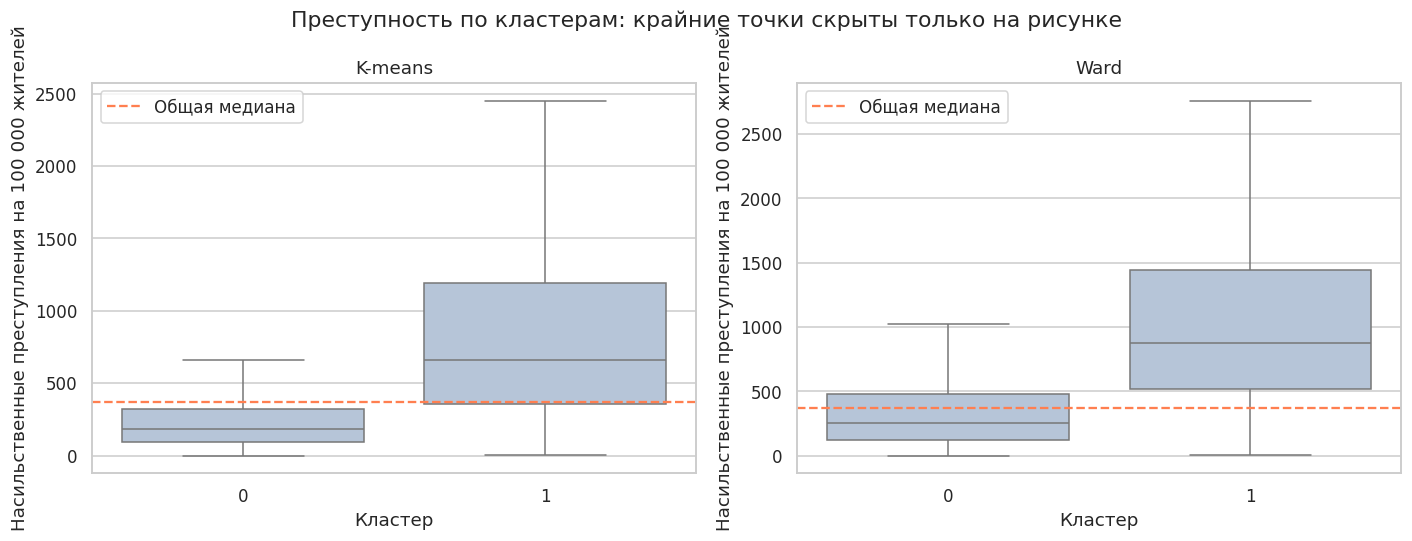

In [14]:
def pair_jaccard(first_labels, second_labels):
    pair_counts = pair_confusion_matrix(first_labels, second_labels)
    true_positive = float(pair_counts[1, 1])
    false_positive = float(pair_counts[0, 1])
    false_negative = float(pair_counts[1, 0])
    denominator = true_positive + false_positive + false_negative
    return true_positive / denominator if denominator else 1.0

crime_values = df.loc[analysis_index, TARGET]
known_crime_mask = crime_values.notna().to_numpy()
crime_threshold = crime_values.dropna().median()
external_labels = (crime_values.loc[crime_values.notna()] > crime_threshold).astype(int).to_numpy()
external_rows = []
crime_profile_rows = []
for method, labels in labels_by_method.items():
    observed_labels = labels[known_crime_mask]
    external_rows.append({
        'Метод': method, 'Объектов с внешней меткой': len(external_labels),
        'Rand': rand_score(external_labels, observed_labels),
        'ARI': adjusted_rand_score(external_labels, observed_labels),
        'NMI': normalized_mutual_info_score(external_labels, observed_labels),
        'Jaccard (пары)': pair_jaccard(external_labels, observed_labels),
    })
    print(f'{method}: сопоставление с условным уровнем преступности')
    display(pd.crosstab(
        pd.Series(observed_labels, name='Кластер'),
        pd.Series(external_labels, name='Высокая преступность'),
    ))
    for cluster in np.unique(labels):
        values = crime_values.iloc[np.flatnonzero(labels == cluster)].dropna()
        crime_profile_rows.append({
            'Метод': method, 'Кластер': cluster, 'Всего объектов': int(np.sum(labels == cluster)),
            'С известной преступностью': len(values),
            'Средняя преступность': values.mean(), 'Медиана преступности': values.median(),
            'Доля выше общей медианы': (values > crime_threshold).mean(),
        })
external_quality = pd.DataFrame(external_rows).set_index('Метод')
crime_profiles = pd.DataFrame(crime_profile_rows)
print(f'Порог внешнего ориентира: {crime_threshold:.2f} преступлений на 100 000 жителей.')
print(f'Только из внешней оценки исключено пропусков: {(~known_crime_mask).sum()}.')
display(external_quality.round(4))
display(crime_profiles.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, METHODS):
    plotting = pd.DataFrame({'Кластер': labels_by_method[method], TARGET: crime_values.to_numpy()})
    sns.boxplot(data=plotting, x='Кластер', y=TARGET, showfliers=False,
                color='lightsteelblue', ax=ax)
    ax.axhline(crime_threshold, linestyle='--', color='coral', label='Общая медиана')
    ax.set(title=method, ylabel='Насильственные преступления на 100 000 жителей')
    ax.legend()
fig.suptitle('Преступность по кластерам: крайние точки скрыты только на рисунке')
plt.tight_layout()
plt.show()

**K-means:** ARI=0.281, NMI=0.220. Наименьшая медиана преступности — в группе 0 (183.1), наибольшая — в группе 1 (660.3).

**Ward:** ARI=0.182, NMI=0.173. Наименьшая медиана преступности — в группе 0 (250.4), наибольшая — в группе 1 (874.9).

Различие по преступности дополняет интерпретацию групп, но не доказывает причинную связь. Искусственная бинаризация теряет информацию о непрерывном показателе; неполное совпадение с ней само по себе не означает плохую кластеризацию.

## 11. Исследование влияния параметра k у K-means

Подробно рассмотрим результаты перебора k: уменьшение SSE ожидаемо при увеличении числа
кластеров, поэтому по одному этому показателю выбирать k нельзя. Сопоставим силуэт,
CH, DB, минимальный размер группы и относительное уменьшение SSE.

,Silhouette,Calinski–Harabasz,Davies–Bouldin,SSE,Минимальный кластер,Максимальный кластер,"Снижение SSE относительно k−1, %",Выбрано по силуэту
k,,,,,,,,
2,0.2765,1053.0766,1.3571,17816.3838,988,1209,32.4215,True
3,0.1833,767.4242,1.7171,15512.1930,634,872,12.9330,False
4,0.1844,642.8584,1.6138,14027.7077,275,748,9.5698,False
5,0.1566,554.9797,1.7256,13098.5840,246,546,6.6235,False
6,0.1556,497.5818,1.7991,12345.5113,196,506,5.7493,False
7,0.1468,461.9710,1.7033,11636.2724,183,489,5.7449,False
8,0.1559,434.0880,1.6372,11039.6017,102,472,5.1277,False
9,0.1560,406.0495,1.6386,10610.7860,103,452,3.8843,False
10,0.1459,384.8334,1.6329,10204.0630,98,398,3.8331,False


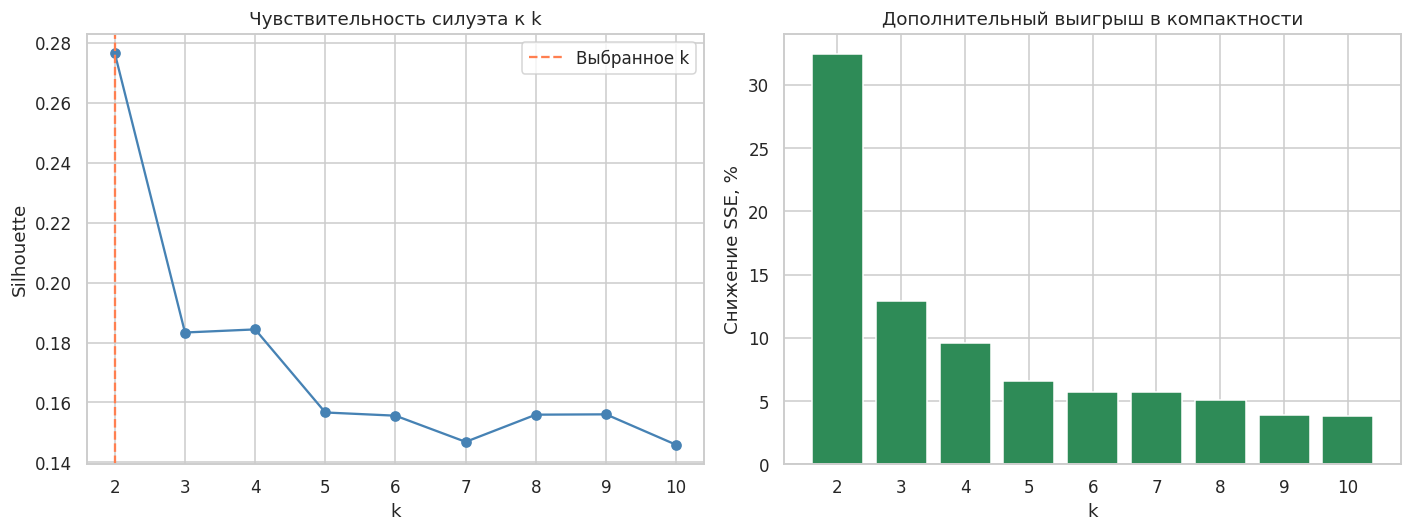

In [15]:
k_sensitivity = km_search.copy().set_index('k')
previous_sse = np.r_[elbow_sse[0], k_sensitivity['SSE'].to_numpy()[:-1]]
k_sensitivity['Снижение SSE относительно k−1, %'] = (
    (previous_sse - k_sensitivity['SSE'].to_numpy()) / previous_sse * 100
)
k_sensitivity['Выбрано по силуэту'] = k_sensitivity.index == best_k['K-means']
display(k_sensitivity.drop(columns='Метод').round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(k_sensitivity.index, k_sensitivity['Silhouette'], 'o-', color='steelblue')
axes[0].axvline(best_k['K-means'], color='coral', linestyle='--', label='Выбранное k')
axes[0].set(title='Чувствительность силуэта к k', xlabel='k', ylabel='Silhouette')
axes[0].legend()
axes[1].bar(k_sensitivity.index, k_sensitivity['Снижение SSE относительно k−1, %'], color='seagreen')
axes[1].set(title='Дополнительный выигрыш в компактности', xlabel='k', ylabel='Снижение SSE, %')
for ax in axes:
    ax.set_xticks(K_VALUES)
plt.tight_layout()
plt.show()

Влияние k: лучший силуэт получен при k=2, наибольший CH — при k=2, наименьший DB — при k=2. SSE уменьшилась с 17816.4 при k=2 до 10204.1 при k=10. Рост числа групп улучшает подгонку по SSE, но не обязательно усиливает разделение по силуэту. Итоговое k=2 сохранено согласно заранее выбранному критерию.

## 12. Устойчивость и согласованность методов

Проверяются три аспекта:

1. Согласованность итоговых разбиений K-means и Уорда с помощью ARI, NMI и таблицы пересечений.
2. Зависимость K-means от случайной инициализации: 10 значений random_state, в каждом n_init=10.
3. Устойчивость обоих методов при удалении случайных 20% объектов: 10 повторов; ARI считается
   между новым разбиением подвыборки и исходными метками тех же объектов.

В экспериментах с подвыборками сохраняются выбранные признаки, преобразования и scaler,
чтобы отдельно исследовать устойчивость самих алгоритмов. Полная неопределённость всего
процесса подготовки этим тестом не оценивается. Для Ward случайные начальные центры
не используются, поэтому исследуется именно изменение состава объектов.

Согласованность методов: ARI=0.2561; NMI=0.3622; попарный Jaccard=0.4887.


Ward,0,1
K-means,,
0,988,0
1,541,668


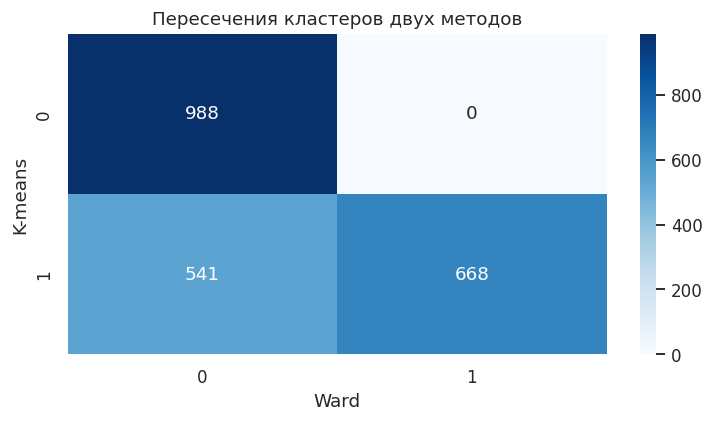

,random_state,ARI к итоговому K-means,SSE
0,0,1.0,17816.3989
1,1,1.0,17816.3838
2,2,1.0,17816.3838
3,3,1.0,17816.3838
4,4,1.0,17816.3989
5,5,1.0,17816.3989
6,6,1.0,17816.3838
7,7,1.0,17816.3838
8,8,1.0,17816.3838
9,9,1.0,17816.3838


,mean,std,min,max
Метод,,,,
K-means,0.9826,0.0133,0.9483,0.9977
Ward,0.3639,0.2826,-0.0233,0.7993


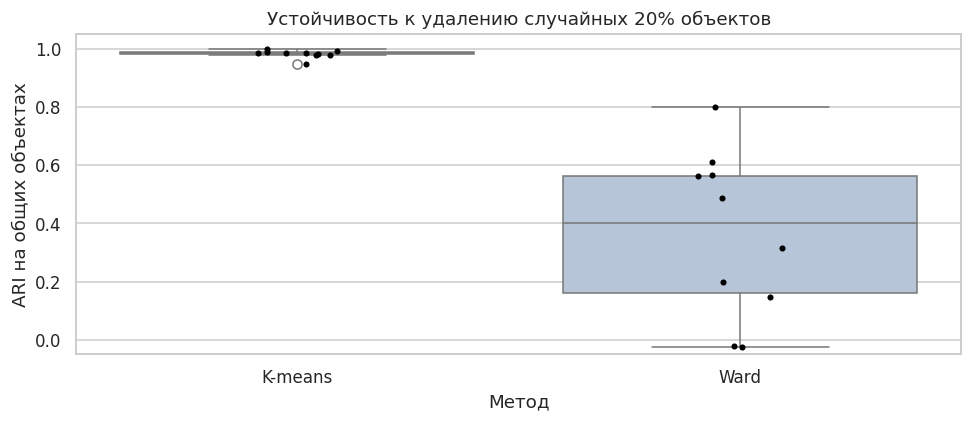

In [16]:
agreement_ari = adjusted_rand_score(labels_by_method['K-means'], labels_by_method['Ward'])
agreement_nmi = normalized_mutual_info_score(labels_by_method['K-means'], labels_by_method['Ward'])
agreement_jaccard = pair_jaccard(labels_by_method['K-means'], labels_by_method['Ward'])
print(f'Согласованность методов: ARI={agreement_ari:.4f}; NMI={agreement_nmi:.4f}; '
      f'попарный Jaccard={agreement_jaccard:.4f}.')
overlap = pd.crosstab(pd.Series(labels_by_method['K-means'], name='K-means'),
                      pd.Series(labels_by_method['Ward'], name='Ward'))
display(overlap)
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(overlap, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_title('Пересечения кластеров двух методов')
plt.tight_layout()
plt.show()

initialization_rows = []
for seed in range(10):
    candidate = KMeans(n_clusters=best_k['K-means'], n_init=10, max_iter=500,
                       random_state=seed).fit(X_scaled)
    initialization_rows.append({
        'random_state': seed,
        'ARI к итоговому K-means': adjusted_rand_score(labels_by_method['K-means'], candidate.labels_),
        'SSE': candidate.inertia_,
    })
initialization_stability = pd.DataFrame(initialization_rows)
display(initialization_stability.round(4))

stability_rows = []
for repeat in range(10):
    rng = np.random.default_rng(RANDOM_STATE + repeat)
    subset = np.sort(rng.choice(len(X_scaled), size=int(0.8 * len(X_scaled)), replace=False))
    subset_values = X_scaled[subset]
    for method in METHODS:
        estimator = (KMeans(n_clusters=best_k[method], n_init=10, max_iter=500,
                            random_state=RANDOM_STATE + repeat)
                     if method == 'K-means' else
                     AgglomerativeClustering(n_clusters=best_k[method], linkage='ward'))
        new_labels = estimator.fit_predict(subset_values)
        stability_rows.append({
            'Метод': method, 'Повтор': repeat + 1,
            'ARI на общих объектах': adjusted_rand_score(labels_by_method[method][subset], new_labels),
        })
stability_results = pd.DataFrame(stability_rows)
stability_summary = stability_results.groupby('Метод')['ARI на общих объектах'].agg(
    ['mean', 'std', 'min', 'max'])
display(stability_summary.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=stability_results, x='Метод', y='ARI на общих объектах', color='lightsteelblue', ax=ax)
sns.stripplot(data=stability_results, x='Метод', y='ARI на общих объектах', color='black', size=4, ax=ax)
ax.set(title='Устойчивость к удалению случайных 20% объектов', ylim=(-0.05, 1.05))
plt.tight_layout()
plt.show()

Результат проверки устойчивости. Между методами ARI=0.256. При смене начальных инициализаций K-means средний ARI к итоговой модели равен 1.000, минимальный — 1.000. При удалении 20% объектов средний ARI равен 0.983 для K-means и 0.364 для Уорда. Значения ближе к 1 означают более воспроизводимое разбиение; устойчивость не равнозначна хорошему разделению групп.

## 13. Чувствительность к обработке экстремальных наблюдений

Повторим обучение на всех исходных объектах: сохраняются выбранные признаки и правило log1p,
но StandardScaler переобучается на полной выборке. Для сопоставимости сохраняется ранее выбранное
k каждого метода. ARI вычисляется на общих, ранее оставленных объектах.
Он показывает, меняются ли основные группы после возвращения экстремальных наблюдений.
Силуэты полной и очищенной выборок описывают разные наборы объектов и не являются
строго парным сравнением качества.

In [17]:
all_scaler = StandardScaler()
X_all_scaled = all_scaler.fit_transform(X_transformed_all)
sensitivity_rows = []
for method in METHODS:
    estimator = (KMeans(n_clusters=best_k[method], n_init=10, max_iter=500, random_state=RANDOM_STATE)
                 if method == 'K-means' else
                 AgglomerativeClustering(n_clusters=best_k[method], linkage='ward'))
    all_labels = estimator.fit_predict(X_all_scaled)
    sensitivity_rows.append({
        'Метод': method, 'k': best_k[method], 'Объектов без удаления': len(all_labels),
        'Silhouette без удаления': silhouette_score(X_all_scaled, all_labels),
        'Silhouette после удаления': quality.loc[method, 'Silhouette'],
        'ARI на общих объектах': adjusted_rand_score(
            labels_by_method[method], all_labels[inlier_mask.to_numpy()]),
    })
outlier_sensitivity = pd.DataFrame(sensitivity_rows).set_index('Метод')
display(outlier_sensitivity.round(4))

,k,Объектов без удаления,Silhouette без удаления,Silhouette после удаления,ARI на общих объектах
Метод,,,,,
K-means,2,2215,0.2765,0.2765,0.9891
Ward,2,2215,0.2473,0.2256,0.0872


Возвращение экстремальных наблюдений: K-means: ARI=0.989; Ward: ARI=0.087. Чем ниже ARI, тем сильнее итоговое разбиение зависит от решения об исключении хвостов. Это ограничение учитывается вместе с устойчивостью к подвыборкам; удалённые населённые пункты могут быть реальными редкими профилями.

## 14. Итоговое сравнение и выводы

Сопоставим внутреннее качество, условное внешнее соответствие, устойчивость и содержательную
интерпретацию. Единственный метод не объявляется «истинным» только по одной метрике.

In [18]:
comparison = quality[['k', 'Silhouette', 'Calinski–Harabasz', 'Davies–Bouldin']].copy()
comparison['ARI к условным классам преступности'] = external_quality['ARI']
comparison['NMI к условным классам преступности'] = external_quality['NMI']
comparison['ARI устойчивости, среднее'] = stability_summary['mean']
comparison['ARI при возвращении экстремумов'] = outlier_sensitivity['ARI на общих объектах']
display(comparison.round(4))

assert len(X_scaled) == len(analysis_index) == int(inlier_mask.sum())
assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_scaled.std(axis=0), 1, atol=1e-10)
assert not X_transformed.isna().any().any()
assert set(selected_features).isdisjoint(SERVICE_COLUMNS + CRIME_COLUMNS)
for method, labels in labels_by_method.items():
    assert len(np.unique(labels)) == best_k[method]
    assert len(labels) == len(X_scaled)
    measured_sse = cluster_geometry.loc[cluster_geometry['Метод'] == method, 'SSE'].sum()
    assert np.isclose(measured_sse, quality.loc[method, 'SSE'])
    assert np.allclose(silhouette_values[method].mean(), quality.loc[method, 'Silhouette'])
assert len(external_labels) == int(known_crime_mask.sum())
print('Проверки размерностей, масштабирования, отсутствия утечки и согласованности метрик пройдены.')

,k,Silhouette,Calinski–Harabasz,Davies–Bouldin,ARI к условным классам преступности,NMI к условным классам преступности,"ARI устойчивости, среднее",ARI при возвращении экстремумов
Метод,,,,,,,,
K-means,2,0.2765,1053.0766,1.3571,0.2809,0.2203,0.9826,0.9891
Ward,2,0.2256,748.5448,1.4511,0.1821,0.1731,0.3639,0.0872


Проверки размерностей, масштабирования, отсутствия утечки и согласованности метрик пройдены.


**Вывод**

1. Исследован набор из 2215 объектов и 147 столбцов.
   Для кластеризации выбрано 12 числовых признаков без показателей
   преступности и идентификаторов. Пропуски и избыточность проверены до построения моделей.
2. Сильно асимметричные признаки преобразованы log1p; по фиксированным границам 3 IQR
   исключено 18 объектов. Основная выборка — 2197 объектов.
   Перед обоими методами выполнен `StandardScaler`.
3. По максимуму силуэта выбрано k=2 для K-means и
   k=2 для Уорда. Эвристика локтя K-means даёт k=3;
   дендрограмма позволяет сопоставить разные уровни детализации.
4. По силуэту предпочтительнее K-means
   (0.277); по CH — K-means,
   по DB — K-means. Уровень разделения оценивается по силуэту вместе с геометрией групп; границы кластеров остаются модельным описанием данных.
5. Полученные группы различаются прежде всего по PctPopUnderPov, PctKids2Par, medIncome.
   Их средние профили описаны выше; преступность сравнивается только после кластеризации.
   ARI к условному делению преступности равен 0.281
   для K-means и 0.182 для Уорда.
   Это соответствие внешнему ориентиру, а не точность предсказания истинного класса.
6. Согласованность двух методов: ARI=0.256
   При изменении состава выборки более устойчив K-means
   (средний ARI=0.983).
   Дополнительно проверены начальные инициализации K-means и возвращение экстремальных объектов.
7. Увеличение k уменьшает SSE, но не гарантирует улучшения силуэта.
   Выделенные группы зависят от выбранных признаков, масштаба и обработки хвостов;
   они представляют описательные социально-экономические профили данной выборки.
   Первые две PC сохраняют 62.8% дисперсии,
   поэтому двумерные рисунки дают лишь частичное представление о структуре.